Thanks Claude

# READ ME FIRST

- To toggle percentage or raw count plotting in the baseline / policy / reward function comparison plots, go to the cell defining USE_PERCENTAGES and set to True or False as desired.
- You should be able to change / add new plots just by changing the input files. This is vibecoded though, so can't make strong promises.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import re

## Load data

In [2]:
DATA_DIR = "data"
OUTPUT_DIR = "figures"

In [3]:
def load_run(path):
    df = pd.read_csv(path)
    # "categories Pornography" -> "Pornography"
    df["category"] = df["action"].str.replace("categories ", "", regex=False)
    return df.sort_values(["episode", "time"]).reset_index(drop=True)

In [4]:
name_map = {
    "baseline": "Baseline",
    "exp1": "Naive UCB",
    "exp2": "LinUCB",
    "exp3": "LinUCB Shared",
    "exp4": "ClusterLinUCB",
    "exp5": "UCB, partial (VPs)",
    "exp6": "UCB, partial (ASNs)",
    "exp7": "UCB, maj. vote",
}

color_map = {
    "baseline": "grey",
    "exp1": "red",
    "exp2": "green",
    "exp3": "purple",
    "exp4": "orange",
    "exp5": "red",
    "exp6": "red",
    "exp7": "red",
}

line_map = {
    "baseline": "solid",
    "exp1": "solid",
    "exp2": "solid",
    "exp3": "solid",
    "exp4": "solid",
    "exp5": "dotted",
    "exp6": "solid",
    "exp7": "dashed",
}

def get_experiment_name(path):
    exp_num = None
    if "baseline" in path:
        exp_num = "baseline"
    else:
        exp_num = re.search(r"exp\d", path).group(0)
    return name_map[exp_num]

def get_experiment_color(path):
    exp_num = None
    if "baseline" in path:
        exp_num = "baseline"
    else:
        exp_num = re.search(r"exp\d", path).group(0)
    return color_map[exp_num]

def get_experiment_linestyle(path):
    exp_num = None
    if "baseline" in path:
        exp_num = "baseline"
    else:
        exp_num = re.search(r"exp\d", path).group(0)
    return line_map[exp_num]
    

## Over-time comparisons (vs baseline, vs other policies, vs other rewards)

In [5]:
USE_PERCENTAGES = True

In [6]:
def get_times(df):
    return df["time"]

In [7]:
def cumulative_found(df):
    # each blocked measurement is a new censored domain (targets are unique)
    return df["is_blocked"].cumsum().to_numpy()

In [8]:
def convert_to_percentage(run, total_blocked):
    return 100 * (run / total_blocked) if total_blocked > 0 else run
    # return 100 * (run / run[-1]) if run[-1] > 0 else run

In [9]:
def get_best_run_idx(runs):
    # print([run[-1] for run in runs])
    return np.argmax([run[-1] for run in runs])

In [10]:
from itertools import repeat

def get_over_time_compare_data(files):
    runs = list(map(load_run, files))
    times = list(map(lambda df: df["time"], runs))
    names = list(map(get_experiment_name, files))
    colors = list(map(get_experiment_color, files))
    linestyles = list(map(get_experiment_linestyle, files))

    if USE_PERCENTAGES:
        _ = pd.concat(runs)[["targets", "is_blocked"]]
        total_blocked = len(_[_["is_blocked"] == 1].drop_duplicates())
        # print(total_blocked)
        # for run in runs:
        #     print(len(run[["targets", "is_blocked"]].drop_duplicates())) 
        runs = list(map(convert_to_percentage, map(cumulative_found, runs), repeat(total_blocked)))
        # runs = list(map(convert_to_percentage, map(cumulative_found, runs)))
    else:
        runs = list(map(cumulative_found, runs))

    return runs, times, names, colors, linestyles

In [11]:
def plot_comparison(files, country_code):
    runs, times, names, colors, lines = get_over_time_compare_data(files) 
    best_run_idx = get_best_run_idx(runs)
    
    fig, ax = plt.subplots(figsize=(8, 5))
    for _ in range(len(runs)):
        lw = 1
        if "Baseline" in names[_] or _ == best_run_idx:
            lw = 2.5
        ax.plot(times[_], runs[_], label=names[_], color=colors[_], linestyle=lines[_], linewidth=lw)
    
    ax.set_xlabel("Number of Measurements")
    if USE_PERCENTAGES:
        ax.set_ylabel("% of Censored Domains Found")
    else:
        ax.set_ylabel("Num Censored Domains Found")
    ax.set_title(f"{country_code}")
    ax.spines[["top", "right"]].set_visible(False)  # matches the reference style
    ax.legend()

In [12]:
files = [
    f"{DATA_DIR}/exp1/Iran.csv",
    f"{DATA_DIR}/baseline/Iran.csv"
]

get_over_time_compare_data(files) 


([array([ 0.0965251 ,  0.19305019,  0.28957529, ..., 83.3976834 ,
         83.3976834 , 83.3976834 ], shape=(2000,)),
  array([ 0.        ,  0.        ,  0.0965251 , ..., 36.96911197,
         37.06563707, 37.06563707], shape=(2000,))],
 [0          1
  1          2
  2          3
  3          4
  4          5
          ... 
  1995    1996
  1996    1997
  1997    1998
  1998    1999
  1999    2000
  Name: time, Length: 2000, dtype: int64,
  0          1
  1          2
  2          3
  3          4
  4          5
          ... 
  1995    1996
  1996    1997
  1997    1998
  1998    1999
  1999    2000
  Name: time, Length: 2000, dtype: int64],
 ['Naive UCB', 'Baseline'],
 ['red', 'grey'],
 ['solid', 'solid'])

### vs baseline

In [13]:
COMPARE_BASELINE_DIR = "./figures/compare_baseline"

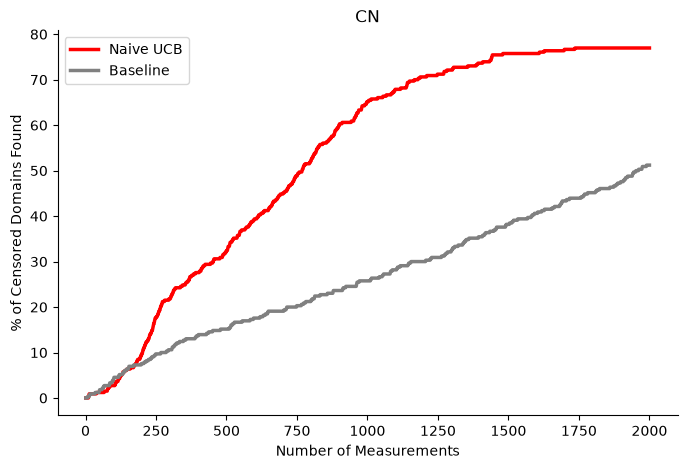

In [14]:
files = [
    f"{DATA_DIR}/exp1/China.csv",
    f"{DATA_DIR}/baseline/China.csv"
]

plot_comparison(files, "CN")

plt.savefig(f"{COMPARE_BASELINE_DIR}/China.pdf", format="pdf", bbox_inches='tight', dpi=300)
plt.show()

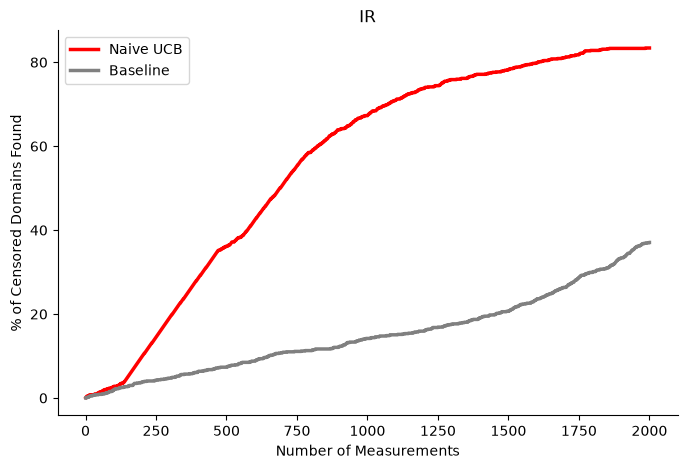

In [15]:
files = [
    f"{DATA_DIR}/exp1/Iran.csv",
    f"{DATA_DIR}/baseline/Iran.csv"
]

plot_comparison(files, "IR")

plt.savefig(f"{COMPARE_BASELINE_DIR}/Iran.pdf", format="pdf", bbox_inches='tight', dpi=300)
plt.show()

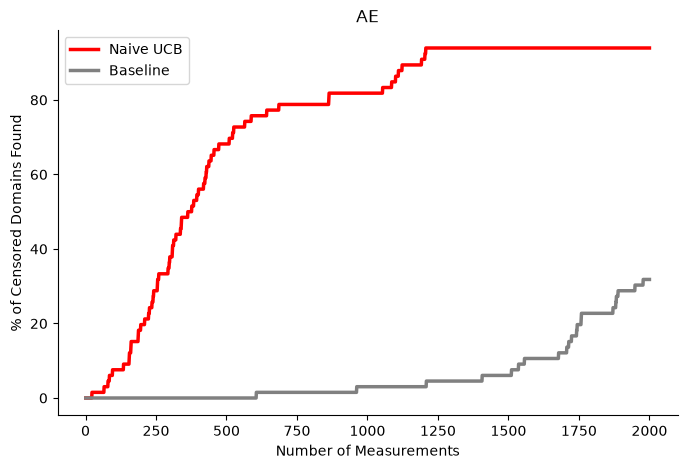

In [16]:
files = [
    f"{DATA_DIR}/exp1/United_Arab_Emirates.csv",
    f"{DATA_DIR}/baseline/United_Arab_Emirates.csv"
]

plot_comparison(files, "AE")

plt.savefig(f"{COMPARE_BASELINE_DIR}/UAE.pdf", format="pdf", bbox_inches='tight', dpi=300)
plt.show()

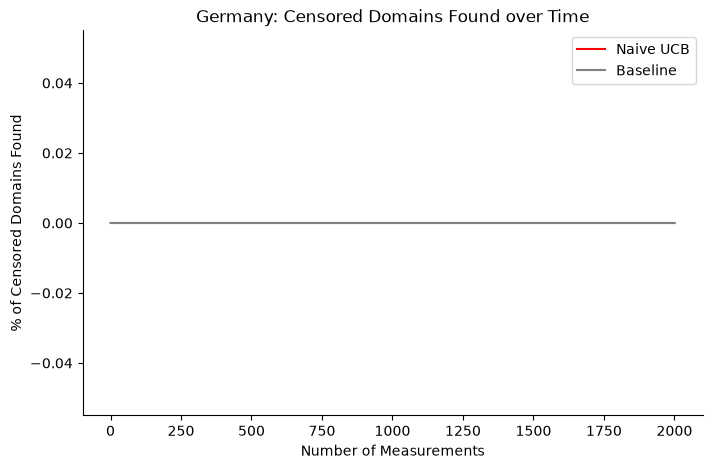

In [17]:
files = [
    f"{DATA_DIR}/exp1/Germany.csv",
    f"{DATA_DIR}/baseline/Germany.csv"
]
runs, times, names, colors, lines = get_over_time_compare_data(files) 

fig, ax = plt.subplots(figsize=(8, 5))
for _ in range(len(runs)):
    ax.plot(times[_], runs[_], label=names[_], color=colors[_], linestyle=lines[_])

ax.set_xlabel("Number of Measurements")
if USE_PERCENTAGES:
    ax.set_ylabel("% of Censored Domains Found")
else:
    ax.set_ylabel("Num Censored Domains Found")
ax.set_title("Germany: Censored Domains Found over Time")
ax.spines[["top", "right"]].set_visible(False)  # matches the reference style
ax.legend()
plt.show()

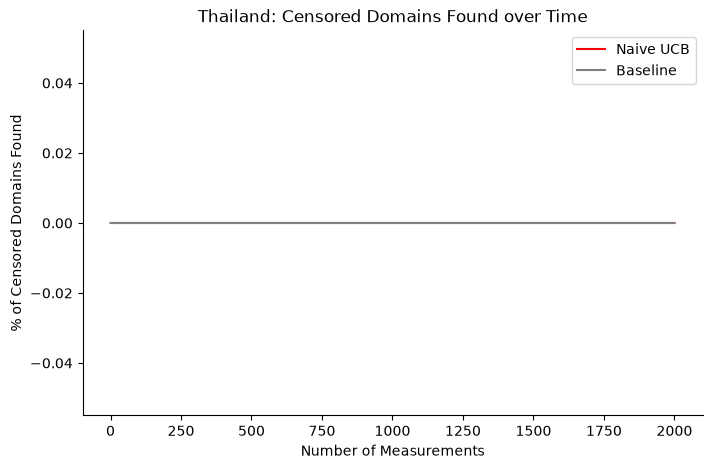

In [18]:
files = [
    f"{DATA_DIR}/exp1/Thailand.csv",
    f"{DATA_DIR}/baseline/Thailand.csv"
]
runs, times, names, colors, lines = get_over_time_compare_data(files) 

fig, ax = plt.subplots(figsize=(8, 5))
for _ in range(len(runs)):
    ax.plot(times[_], runs[_], label=names[_], color=colors[_], linestyle=lines[_])

ax.set_xlabel("Number of Measurements")
if USE_PERCENTAGES:
    ax.set_ylabel("% of Censored Domains Found")
else:
    ax.set_ylabel("Num Censored Domains Found")
ax.set_title("Thailand: Censored Domains Found over Time")
ax.spines[["top", "right"]].set_visible(False)  # matches the reference style
ax.legend()
plt.show()

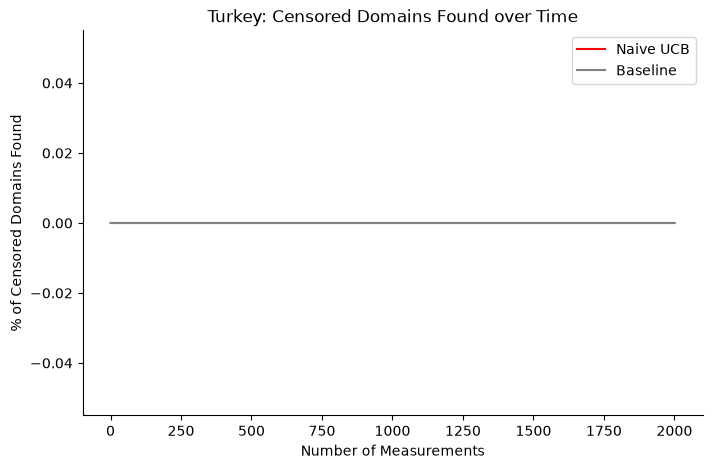

In [19]:
files = [
    f"{DATA_DIR}/exp1/Turkey.csv",
    f"{DATA_DIR}/baseline/Turkey.csv"
]
runs, times, names, colors, lines = get_over_time_compare_data(files) 

fig, ax = plt.subplots(figsize=(8, 5))
for _ in range(len(runs)):
    ax.plot(times[_], runs[_], label=names[_], color=colors[_], linestyle=lines[_])

ax.set_xlabel("Number of Measurements")
if USE_PERCENTAGES:
    ax.set_ylabel("% of Censored Domains Found")
else:
    ax.set_ylabel("Num Censored Domains Found")
ax.set_title("Turkey: Censored Domains Found over Time")
ax.spines[["top", "right"]].set_visible(False)  # matches the reference style
ax.legend()
plt.show()

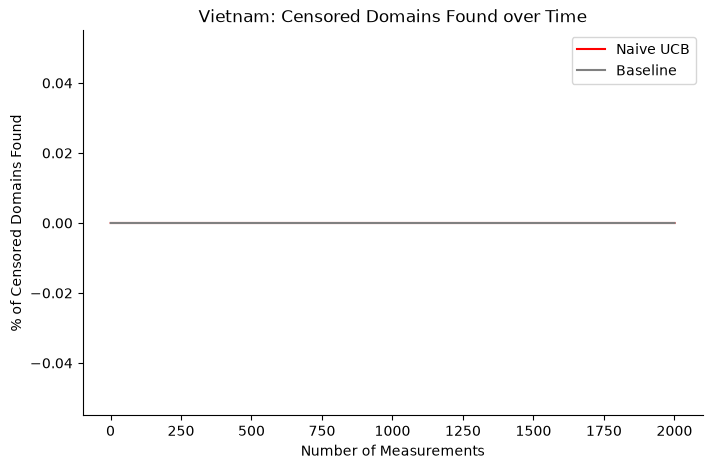

In [20]:
files = [
    f"{DATA_DIR}/exp1/Vietnam.csv",
    f"{DATA_DIR}/baseline/Vietnam.csv"
]
runs, times, names, colors, lines = get_over_time_compare_data(files) 

fig, ax = plt.subplots(figsize=(8, 5))
for _ in range(len(runs)):
    ax.plot(times[_], runs[_], label=names[_], color=colors[_], linestyle=lines[_])

ax.set_xlabel("Number of Measurements")
if USE_PERCENTAGES:
    ax.set_ylabel("% of Censored Domains Found")
else:
    ax.set_ylabel("Num Censored Domains Found")
ax.set_title("Vietnam: Censored Domains Found over Time")
ax.spines[["top", "right"]].set_visible(False)  # matches the reference style
ax.legend()
plt.show()

### Policy comparison

In [21]:
COMPARE_POLICY_DIR = "./figures/compare_policy"

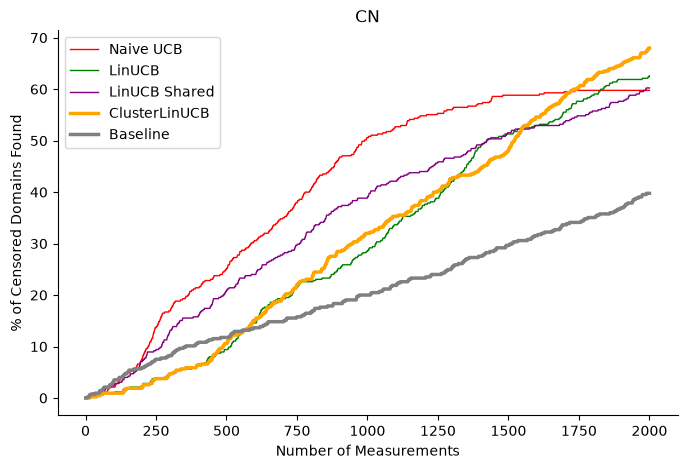

In [22]:
files = [
    f"{DATA_DIR}/exp1/China.csv",
    f"{DATA_DIR}/exp2/China.csv",
    f"{DATA_DIR}/exp3/China.csv",
    f"{DATA_DIR}/exp4/China.csv",
    f"{DATA_DIR}/baseline/China.csv"
]

plot_comparison(files, "CN")

plt.savefig(f"{COMPARE_POLICY_DIR}/China.pdf", format="pdf", bbox_inches='tight', dpi=300)
plt.show()

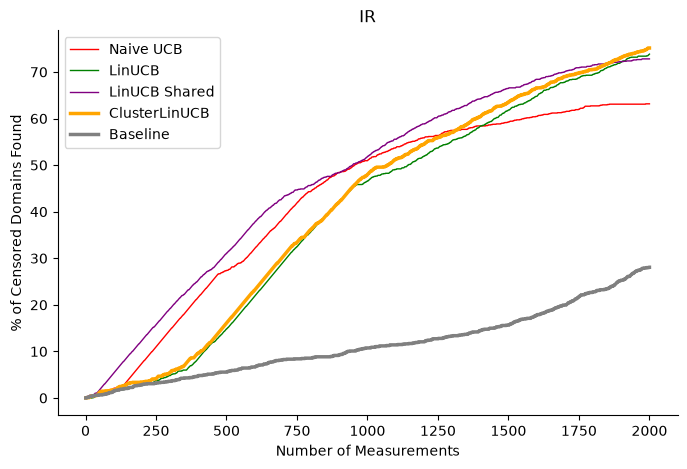

In [23]:
files = [
    f"{DATA_DIR}/exp1/Iran.csv",
    f"{DATA_DIR}/exp2/Iran.csv",
    f"{DATA_DIR}/exp3/Iran.csv",
    f"{DATA_DIR}/exp4/Iran.csv",
    f"{DATA_DIR}/baseline/Iran.csv"
]

plot_comparison(files, "IR")

plt.savefig(f"{COMPARE_POLICY_DIR}/Iran.pdf", format="pdf", bbox_inches='tight', dpi=300)
plt.show()

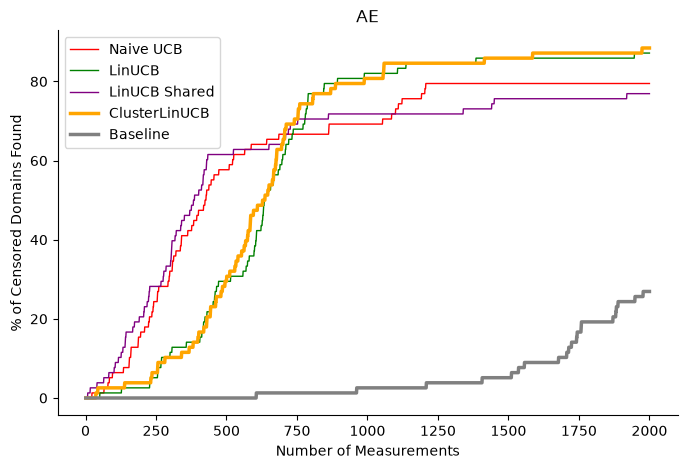

In [24]:
files = [
    f"{DATA_DIR}/exp1/United_Arab_Emirates.csv",
    f"{DATA_DIR}/exp2/United_Arab_Emirates.csv",
    f"{DATA_DIR}/exp3/United_Arab_Emirates.csv",
    f"{DATA_DIR}/exp4/United_Arab_Emirates.csv",
    f"{DATA_DIR}/baseline/United_Arab_Emirates.csv"
]

plot_comparison(files, "AE")

plt.savefig(f"{COMPARE_POLICY_DIR}/UAE.pdf", format="pdf", bbox_inches='tight', dpi=300)
plt.show()

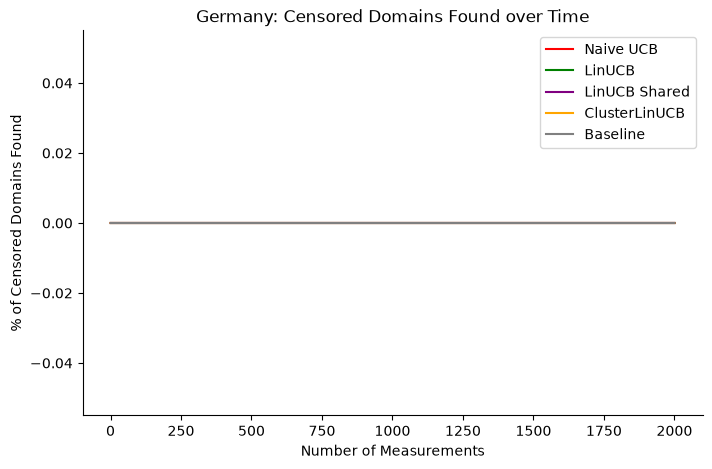

In [25]:
files = [
    f"{DATA_DIR}/exp1/Germany.csv",
    f"{DATA_DIR}/exp2/Germany.csv",
    f"{DATA_DIR}/exp3/Germany.csv",
    f"{DATA_DIR}/exp4/Germany.csv",
    f"{DATA_DIR}/baseline/Germany.csv"
]
runs, times, names, colors, lines = get_over_time_compare_data(files) 

fig, ax = plt.subplots(figsize=(8, 5))
for _ in range(len(runs)):
    ax.plot(times[_], runs[_], label=names[_], color=colors[_], linestyle=lines[_])

ax.set_xlabel("Number of Measurements")
if USE_PERCENTAGES:
    ax.set_ylabel("% of Censored Domains Found")
else:
    ax.set_ylabel("Num Censored Domains Found")
ax.set_title("Germany: Censored Domains Found over Time")
ax.spines[["top", "right"]].set_visible(False)  # matches the reference style
ax.legend()
plt.show()

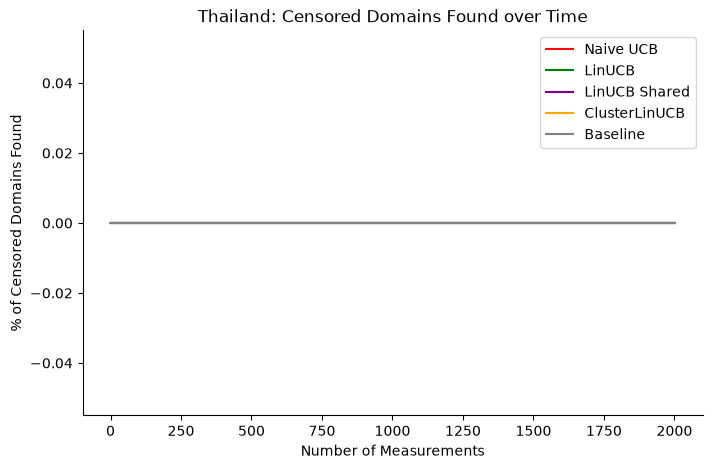

In [26]:
files = [
    f"{DATA_DIR}/exp1/Thailand.csv",
    f"{DATA_DIR}/exp2/Thailand.csv",
    f"{DATA_DIR}/exp3/Thailand.csv",
    f"{DATA_DIR}/exp4/Thailand.csv",
    f"{DATA_DIR}/baseline/Thailand.csv"
]
runs, times, names, colors, lines = get_over_time_compare_data(files) 

fig, ax = plt.subplots(figsize=(8, 5))
for _ in range(len(runs)):
    ax.plot(times[_], runs[_], label=names[_], color=colors[_], linestyle=lines[_])

ax.set_xlabel("Number of Measurements")
if USE_PERCENTAGES:
    ax.set_ylabel("% of Censored Domains Found")
else:
    ax.set_ylabel("Num Censored Domains Found")
ax.set_title("Thailand: Censored Domains Found over Time")
ax.spines[["top", "right"]].set_visible(False)  # matches the reference style
ax.legend()
plt.show()

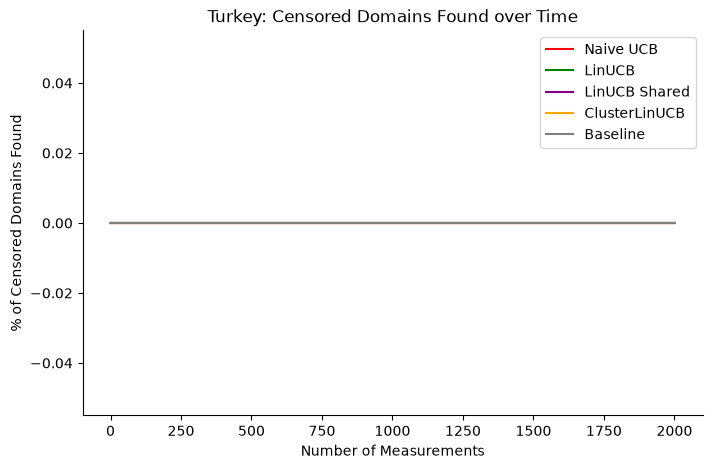

In [27]:
files = [
    f"{DATA_DIR}/exp1/Turkey.csv",
    f"{DATA_DIR}/exp2/Turkey.csv",
    f"{DATA_DIR}/exp3/Turkey.csv",
    f"{DATA_DIR}/exp4/Turkey.csv",
    f"{DATA_DIR}/baseline/Turkey.csv"
]
runs, times, names, colors, lines = get_over_time_compare_data(files) 

fig, ax = plt.subplots(figsize=(8, 5))
for _ in range(len(runs)):
    ax.plot(times[_], runs[_], label=names[_], color=colors[_], linestyle=lines[_])

ax.set_xlabel("Number of Measurements")
if USE_PERCENTAGES:
    ax.set_ylabel("% of Censored Domains Found")
else:
    ax.set_ylabel("Num Censored Domains Found")
ax.set_title("Turkey: Censored Domains Found over Time")
ax.spines[["top", "right"]].set_visible(False)  # matches the reference style
ax.legend()
plt.show()

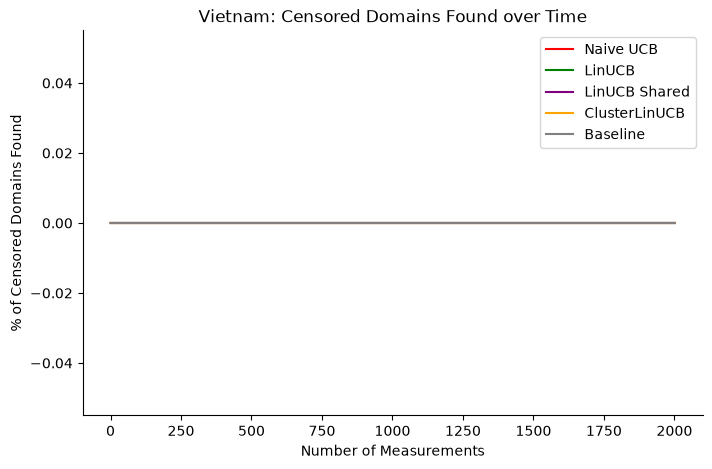

In [28]:
files = [
    f"{DATA_DIR}/exp1/Vietnam.csv",
    f"{DATA_DIR}/exp2/Vietnam.csv",
    f"{DATA_DIR}/exp3/Vietnam.csv",
    f"{DATA_DIR}/exp4/Vietnam.csv",
    f"{DATA_DIR}/baseline/Vietnam.csv"
]
runs, times, names, colors, lines = get_over_time_compare_data(files) 

fig, ax = plt.subplots(figsize=(8, 5))
for _ in range(len(runs)):
    ax.plot(times[_], runs[_], label=names[_], color=colors[_], linestyle=lines[_])

ax.set_xlabel("Number of Measurements")
if USE_PERCENTAGES:
    ax.set_ylabel("% of Censored Domains Found")
else:
    ax.set_ylabel("Num Censored Domains Found")
ax.set_title("Vietnam: Censored Domains Found over Time")
ax.spines[["top", "right"]].set_visible(False)  # matches the reference style
ax.legend()
plt.show()

### Reward comparison

In [29]:
COMPARE_REWARD_DIR = "./figures/compare_reward"

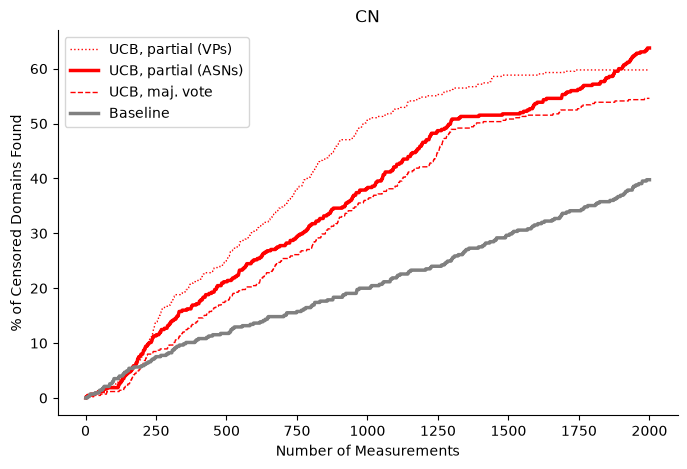

In [30]:
files = [
    f"{DATA_DIR}/exp5/China.csv",
    f"{DATA_DIR}/exp6/China.csv",
    f"{DATA_DIR}/exp7/China.csv",
    f"{DATA_DIR}/baseline/China.csv"
]

plot_comparison(files, "CN")

plt.savefig(f"{COMPARE_REWARD_DIR}/China.pdf", format="pdf", bbox_inches='tight', dpi=300)
plt.show()

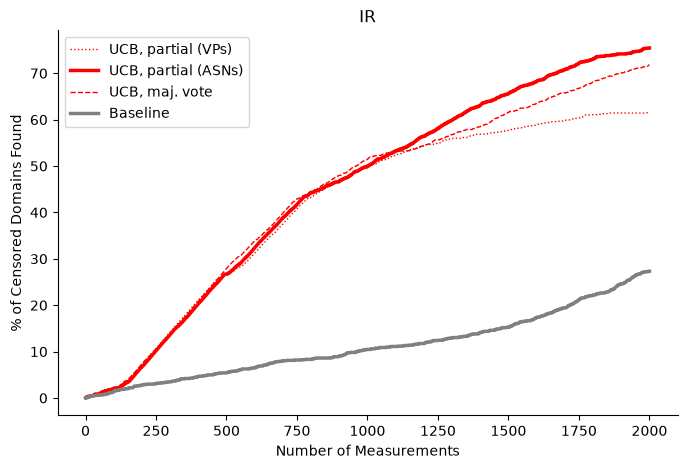

In [31]:
files = [
    f"{DATA_DIR}/exp5/Iran.csv",
    f"{DATA_DIR}/exp6/Iran.csv",
    f"{DATA_DIR}/exp7/Iran.csv",
    f"{DATA_DIR}/baseline/Iran.csv"
]

plot_comparison(files, "IR")

plt.savefig(f"{COMPARE_REWARD_DIR}/Iran.pdf", format="pdf", bbox_inches='tight', dpi=300)
plt.show()

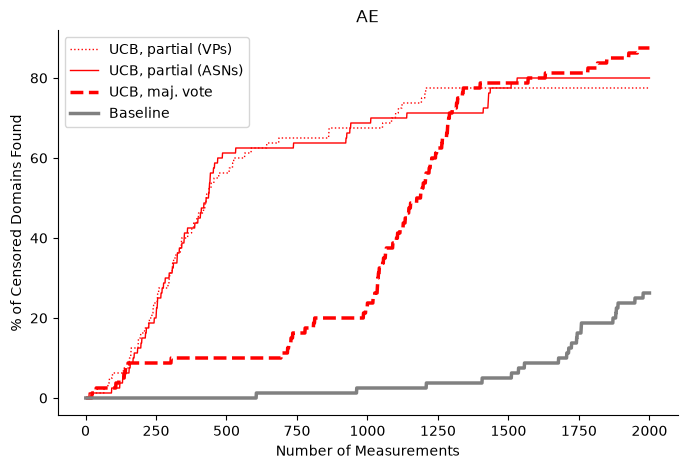

In [32]:
files = [
    f"{DATA_DIR}/exp5/United_Arab_Emirates.csv",
    f"{DATA_DIR}/exp6/United_Arab_Emirates.csv",
    f"{DATA_DIR}/exp7/United_Arab_Emirates.csv",
    f"{DATA_DIR}/baseline/United_Arab_Emirates.csv"
]

plot_comparison(files, "AE")

plt.savefig(f"{COMPARE_REWARD_DIR}/UAE.pdf", format="pdf", bbox_inches='tight', dpi=300)
plt.show()

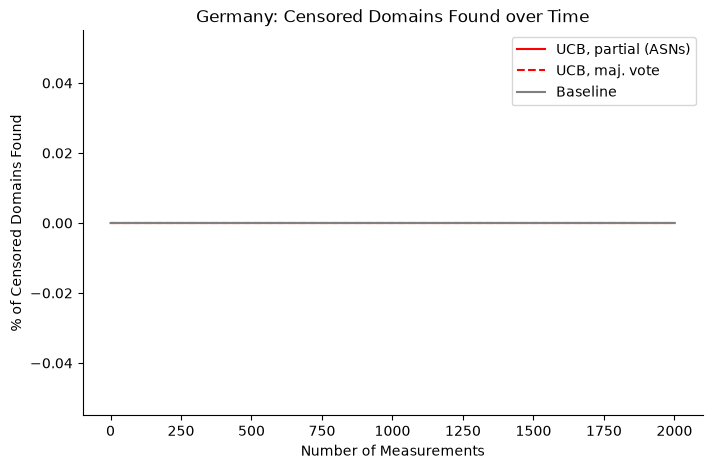

In [33]:
files = [
    # f"{DATA_DIR}/exp5/Germany.csv",
    f"{DATA_DIR}/exp6/Germany.csv",
    f"{DATA_DIR}/exp7/Germany.csv",
    f"{DATA_DIR}/baseline/Germany.csv"
]
runs, times, names, colors, lines = get_over_time_compare_data(files) 

fig, ax = plt.subplots(figsize=(8, 5))
for _ in range(len(runs)):
    ax.plot(times[_], runs[_], label=names[_], color=colors[_], linestyle=lines[_])

ax.set_xlabel("Number of Measurements")
if USE_PERCENTAGES:
    ax.set_ylabel("% of Censored Domains Found")
else:
    ax.set_ylabel("Num Censored Domains Found")
ax.set_title("Germany: Censored Domains Found over Time")
ax.spines[["top", "right"]].set_visible(False)  # matches the reference style
ax.legend()
plt.show()

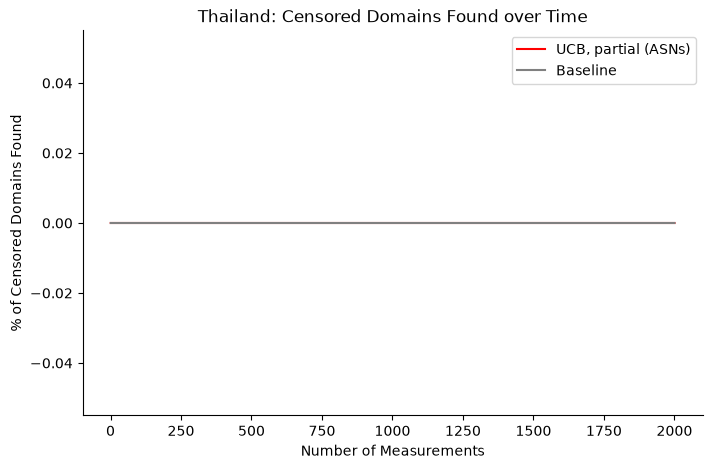

In [34]:
files = [
    # f"{DATA_DIR}/exp5/Thailand.csv",
    f"{DATA_DIR}/exp6/Thailand.csv",
    # f"{DATA_DIR}/exp7/Thailand.csv",
    f"{DATA_DIR}/baseline/Thailand.csv"
]
runs, times, names, colors, lines = get_over_time_compare_data(files) 

fig, ax = plt.subplots(figsize=(8, 5))
for _ in range(len(runs)):
    ax.plot(times[_], runs[_], label=names[_], color=colors[_], linestyle=lines[_])

ax.set_xlabel("Number of Measurements")
if USE_PERCENTAGES:
    ax.set_ylabel("% of Censored Domains Found")
else:
    ax.set_ylabel("Num Censored Domains Found")
ax.set_title("Thailand: Censored Domains Found over Time")
ax.spines[["top", "right"]].set_visible(False)  # matches the reference style
ax.legend()
plt.show()

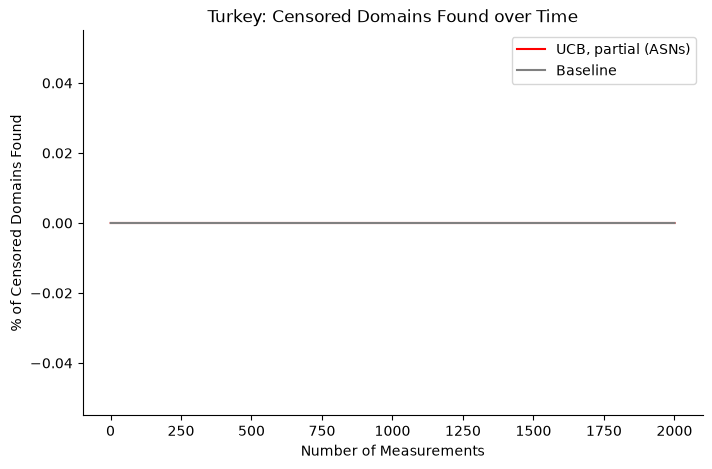

In [35]:
files = [
    # f"{DATA_DIR}/exp5/Turkey.csv",
    f"{DATA_DIR}/exp6/Turkey.csv",
    # f"{DATA_DIR}/exp7/Turkey.csv",
    f"{DATA_DIR}/baseline/Turkey.csv"
]
runs, times, names, colors, lines = get_over_time_compare_data(files) 

fig, ax = plt.subplots(figsize=(8, 5))
for _ in range(len(runs)):
    ax.plot(times[_], runs[_], label=names[_], color=colors[_], linestyle=lines[_])

ax.set_xlabel("Number of Measurements")
if USE_PERCENTAGES:
    ax.set_ylabel("% of Censored Domains Found")
else:
    ax.set_ylabel("Num Censored Domains Found")
ax.set_title("Turkey: Censored Domains Found over Time")
ax.spines[["top", "right"]].set_visible(False)  # matches the reference style
ax.legend()
plt.show()

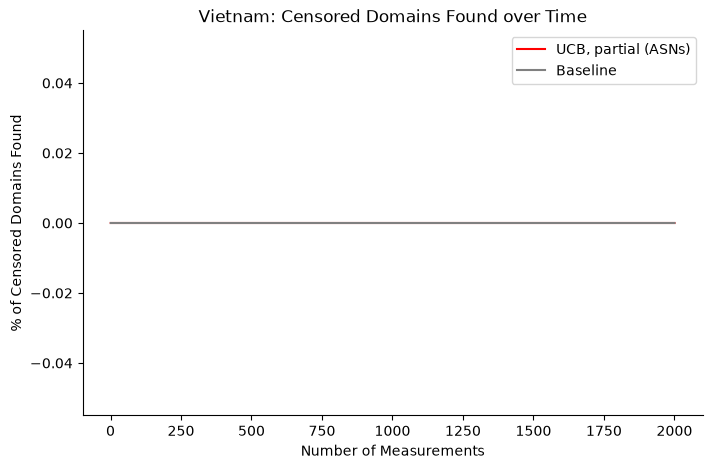

In [36]:
files = [
    # f"{DATA_DIR}/exp5/Vietnam.csv",
    f"{DATA_DIR}/exp6/Vietnam.csv",
    # f"{DATA_DIR}/exp7/Vietnam.csv",
    f"{DATA_DIR}/baseline/Vietnam.csv"
]
runs, times, names, colors, lines = get_over_time_compare_data(files) 

fig, ax = plt.subplots(figsize=(8, 5))
for _ in range(len(runs)):
    ax.plot(times[_], runs[_], label=names[_], color=colors[_], linestyle=lines[_])

ax.set_xlabel("Number of Measurements")
if USE_PERCENTAGES:
    ax.set_ylabel("% of Censored Domains Found")
else:
    ax.set_ylabel("Num Censored Domains Found")
ax.set_title("Vietnam: Censored Domains Found over Time")
ax.spines[["top", "right"]].set_visible(False)  # matches the reference style
ax.legend()
plt.show()

### All (sanity check)

## Box-whisker plot of arm pulls

In [37]:
def get_categories_to_plot(runs, min_domains, num_each):
    # print(runs)
    runs = map(load_run, runs)

    # _ = list(runs)[1]
    # print(_[_["category"] == "News & Media"])
    
    all_measured_domains = pd.concat(runs).drop_duplicates(subset="targets")
    filtered_domains = all_measured_domains.groupby("category").agg(
        n_domains=("targets", "nunique"),
        avg_reward=("rewards", "mean"),
    )
    filtered_domains = filtered_domains[filtered_domains["n_domains"] >= min_domains]
    filtered_domains = filtered_domains.sort_values("avg_reward", ascending=False)
    print(filtered_domains)

    top = list(filtered_domains.index[:num_each])
    bottom = list(filtered_domains.index[-num_each:])
    # dict.fromkeys drops repeats but keeps the order
    selected = list(dict.fromkeys(top + bottom))

    return selected

In [38]:
def get_scatter_plot_data(files, categories):
    runs = map(load_run, files)
    all_categories_per_run = [
        {cat: run[run["category"] == cat] for cat in categories}
        for run in runs
    ]
    category_rewards_per_run = [
        {cat: subs[cat]["rewards"].mean() for cat in categories}
        for subs in all_categories_per_run
    ]
    
    names = list(map(get_experiment_name, files))
    colors = list(map(get_experiment_color, files))
    
    return list(all_categories_per_run), list(category_rewards_per_run), names, colors

In [39]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

def plot_scatter_boxes(files, min_domains, n_each, country_code):
    # pop, readd is to avoid including baseline in get_categories_to_plot
    # Don't include baseline when calculating what categories to plot,
    # since we want to pick the most interesting categories reward-wise
    # and baseline doesn't try to pick "interesting" categories
    baseline, baseline_idx = None, None
    baseline_matches = [_ for _ in files if "baseline" in _]
    if baseline_matches:
        baseline_idx = files.index(baseline_matches[0])
        baseline = files.pop(baseline_idx)
    # _ = files.pop(0)
    categories = get_categories_to_plot(files, min_domains, n_each)
    # files.insert(0, _)
    if baseline_matches:
        files.append(baseline)
    
    # all_categories, category_rewards, names, colors = get_scatter_plot_data(files, categories)
    
    X_AXIS_OFFSET_SCALE = 1
    BETWEEN_BOX_OFFSET_SCALE = 0.3
    PLOT_LENGTH_SCALE = 0.5
    BOX_WIDTH = 0.2
    
    def box_x(i, offset):
        return X_AXIS_OFFSET_SCALE * i + offset * BETWEEN_BOX_OFFSET_SCALE
    
    # plot length should be dependent on # categories and # runs
    num_categories = len(categories)
    num_runs = len(files)
    
    # fig, ax = plt.subplots(figsize=(num_categories * num_runs * PLOT_LENGTH_SCALE, 6))
    fig, ax = plt.subplots(figsize=(12, 6))
    
    # need a list of idx, run subsets, rewards, names, colors
    # run subsets are the measurements that match each category for every category, so actually a 
    
    all_categories, category_rewards, names, colors = get_scatter_plot_data(files, categories)
    
    for i, cat in enumerate(categories):
        for offset, subs, color in zip(range(len(all_categories)), all_categories, colors):
            data = subs[cat]["time"].to_numpy()
            bp = ax.boxplot([data], 
                            positions=[box_x(i, offset)], 
                            widths=BOX_WIDTH,
                            patch_artist=True, showfliers=False,
                            medianprops={"color": "black"})
            bp["boxes"][0].set_facecolor(color)
            bp["boxes"][0].set_alpha(0.4)   # make the box semi-transparent
    
    rng = np.random.default_rng(0)  # fixed seed -> same jitter every run
    
    JITTER_HALF_LENGTH = BOX_WIDTH / 3
    for i, cat in enumerate(categories):
        for offset, subs in zip(range(len(all_categories)), all_categories):
            pts = subs[cat]
            # spread points sideways around the box center (box half-width is 0.5)
            x = box_x(i, offset) + rng.uniform(-JITTER_HALF_LENGTH, JITTER_HALF_LENGTH, size=len(pts))
            point_colors = np.where(pts["is_blocked"] == 1, "crimson", "gray")
            ax.scatter(x, pts["time"], c=point_colors, s=6, alpha=0.5, zorder=3)

    labels = []
    # iterate over cat, then run
    for cat in categories:
        label = cat
        for name, rewards in zip(names, category_rewards):
            if "Baseline" not in name:
                label = f"{label}\n{name}:{rewards[cat]:.2f}"
        labels.append(label)
    
    ax.set_xticks([box_x(i, (num_runs - 1) / 2) for i in range(len(categories))])
    ax.set_xticklabels(labels, fontsize=8)
    
    ax.set_ylabel("Measurement Step")
    ax.set_title(f"{country_code}", pad=22)
    
    # categories before this index are the "top" group, the rest are "bottom"
    split = num_categories // 2
    # halfway between the last box of the previous group and the first box of the next
    divider_x = (box_x(split - 1, num_runs - 1) + box_x(split, 0)) / 2
    ax.axvline(divider_x, color="black", linestyle="--", linewidth=1, alpha=0.5, zorder=0)
    
    # Below is code to add labels to each side on the top
    # can comment out and remove title padding if space needed
    # x-range covered by the boxes on each side of the divider
    left_center = (box_x(0, 0) + box_x(split - 1, num_runs - 1)) / 2
    right_center = (box_x(split, 0) + box_x(num_categories - 1, num_runs - 1)) / 2
    # x in data units, y in axes units (1.0 = top edge of the plot)
    xform = ax.get_xaxis_transform()
    ax.text(left_center, 1.0, "Most censored", transform=xform,
            ha="center", va="bottom", fontsize=10, fontweight="bold")
    ax.text(right_center, 1.0, "Less censored", transform=xform,
            ha="center", va="bottom", fontsize=10, fontweight="bold")
    
    handles = [Patch(color=color, label=name) for color, name in zip(colors, names)]
    handles.append(Line2D([0], [0], marker="o", color="w", markerfacecolor="crimson", label="blocked"))
    handles.append(Line2D([0], [0], marker="o", color="w", markerfacecolor="gray", label="not blocked"))
    ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(0.0, 1.2))
    ax.spines[["top", "right"]].set_visible(False)
    

In [40]:
SCATTER_DIR = "./figures/category_times"

                      n_domains  avg_reward
category                                   
Pornography                 329    0.926322
Social Networks             239    0.797741
Personal Blogs              114    0.286053
Ecommerce                   421    0.137696
Advertisements              132    0.125606
Information Security        103    0.019417


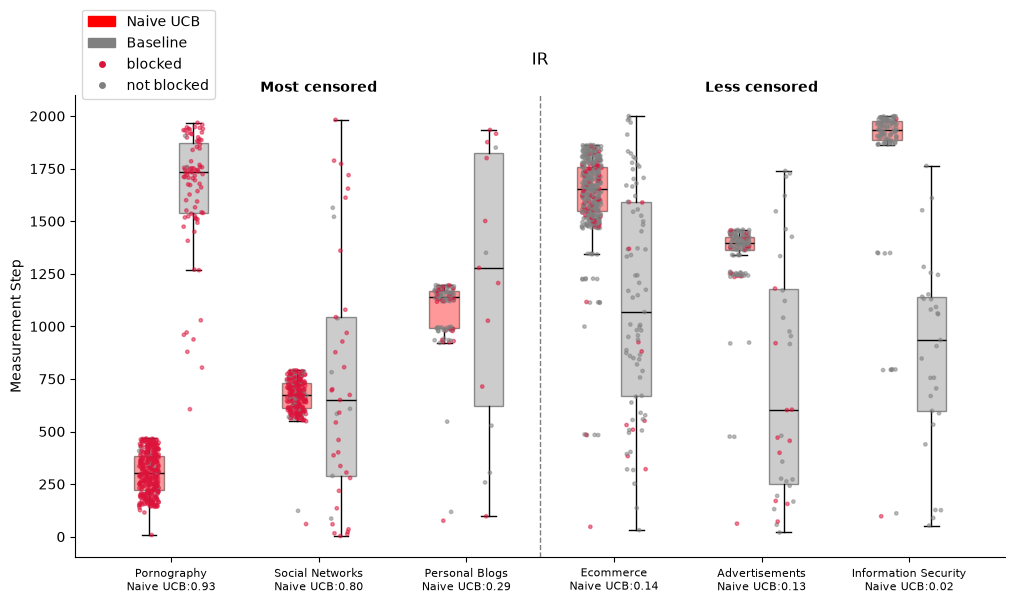

In [41]:
min_domains_Iran = 100   # category must have at least this many distinct domains
n_each_Iran = 3          # how many to take from the top and from the bottom

files_Iran = [
    f"{DATA_DIR}/exp1/Iran.csv",
    # f"{DATA_DIR}/exp3/Iran.csv",
    f"{DATA_DIR}/baseline/Iran.csv"
]

plot_scatter_boxes(files_Iran, min_domains_Iran, n_each_Iran, "IR")
plt.savefig(f"{SCATTER_DIR}/Iran_baseline.pdf", format="pdf", bbox_inches='tight', dpi=300)
plt.show()

                      n_domains  avg_reward
category                                   
Pornography                 329    0.926322
Social Networks             239    0.797741
Video Streaming             394    0.347970
Personal Blogs              114    0.286053
Ecommerce                   421    0.137696
Advertisements              132    0.125606
Information Security        105    0.019048


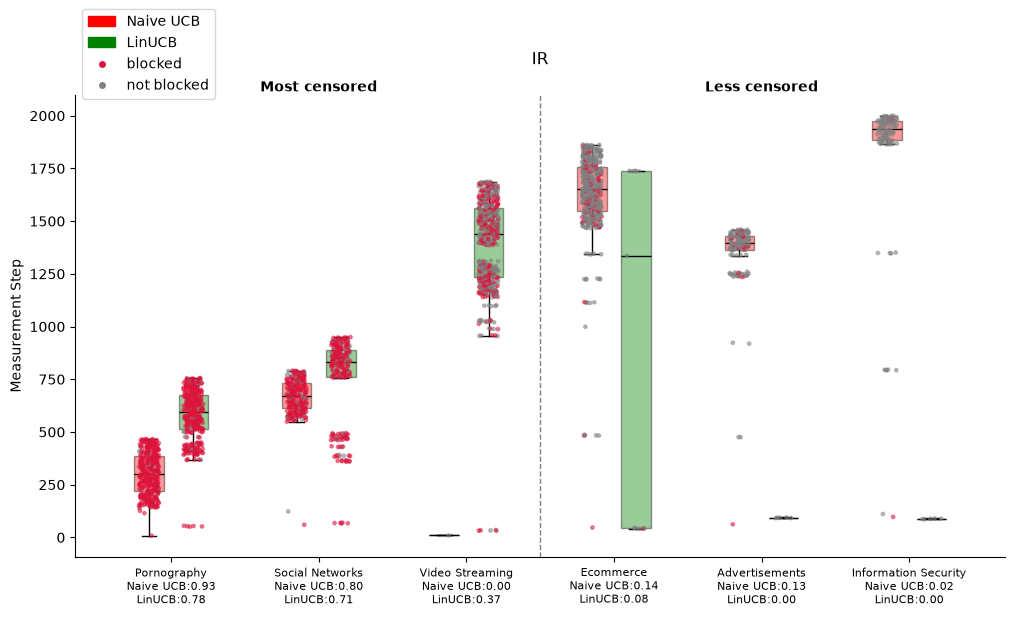

In [42]:
min_domains_Iran = 100   # category must have at least this many distinct domains
n_each_Iran = 3          # how many to take from the top and from the bottom

files_Iran = [
    f"{DATA_DIR}/exp1/Iran.csv",
    f"{DATA_DIR}/exp2/Iran.csv",
    # f"{DATA_DIR}/baseline/Iran.csv"
]

plot_scatter_boxes(files_Iran, min_domains_Iran, n_each_Iran, "IR")
plt.savefig(f"{SCATTER_DIR}/Iran_policy.pdf", format="pdf", bbox_inches='tight', dpi=300)
plt.show()

                      n_domains  avg_reward
category                                   
Pornography                 329    0.926322
Social Networks             239    0.797741
News & Media                805    0.306832
Personal Blogs              114    0.286053
Ecommerce                   421    0.137696
Advertisements              132    0.125606
Information Security        103    0.019417


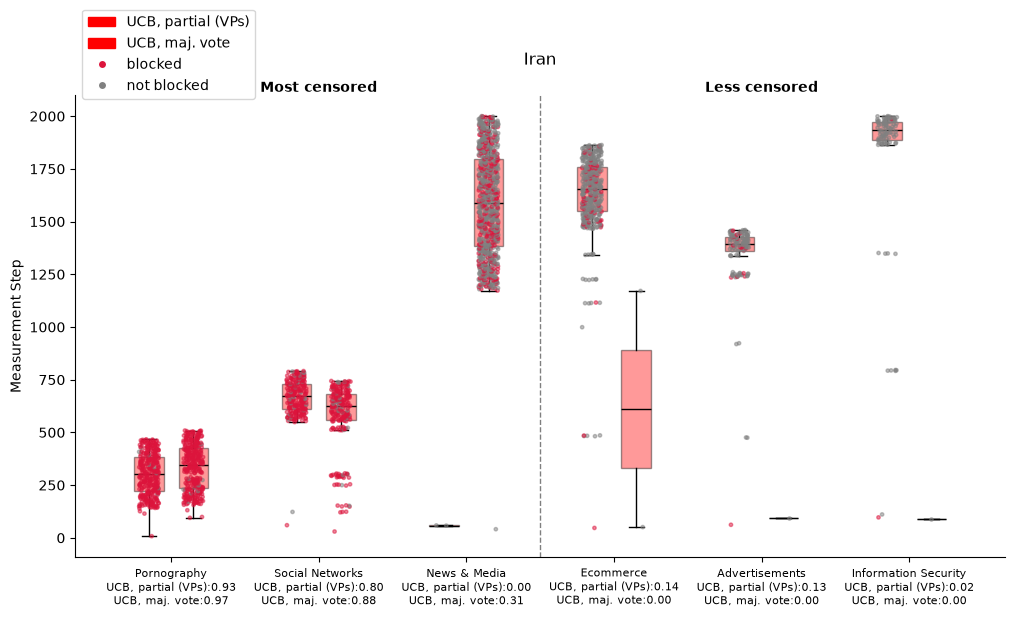

In [43]:
min_domains_Iran = 100   # category must have at least this many distinct domains
n_each_Iran = 3          # how many to take from the top and from the bottom

files_Iran = [
    f"{DATA_DIR}/exp5/Iran.csv",
    f"{DATA_DIR}/exp7/Iran.csv",
    # f"{DATA_DIR}/baseline/Iran.csv"
]

plot_scatter_boxes(files_Iran, min_domains_Iran, n_each_Iran, "Iran")
plt.savefig(f"{SCATTER_DIR}/Iran_reward.pdf", format="pdf", bbox_inches='tight', dpi=300)
plt.show()

### China

                 n_domains  avg_reward
category                              
Video Streaming        535    0.211252
Pornography            326    0.073865
Technology             522    0.009789


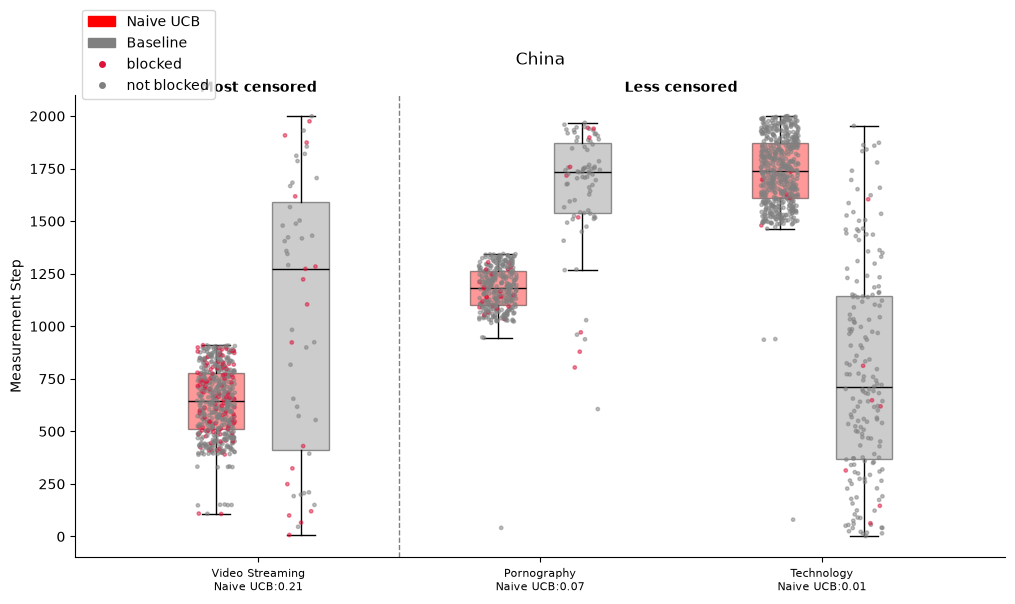

In [44]:
min_domains_China = 100   # category must have at least this many distinct domains
n_each_China = 3          # how many to take from the top and from the bottom

files_China = [
    f"{DATA_DIR}/exp1/China.csv",
    # f"{DATA_DIR}/exp3/China.csv",
    f"{DATA_DIR}/baseline/China.csv"
]

plot_scatter_boxes(files_China, min_domains_China, n_each_China, "China")
plt.savefig(f"{SCATTER_DIR}/China_baseline.pdf", format="pdf", bbox_inches='tight', dpi=300)
plt.show()

                 n_domains  avg_reward
category                              
Video Streaming        535    0.211252
News & Media           110    0.109091
Pornography            326    0.073865
Technology             525    0.009733


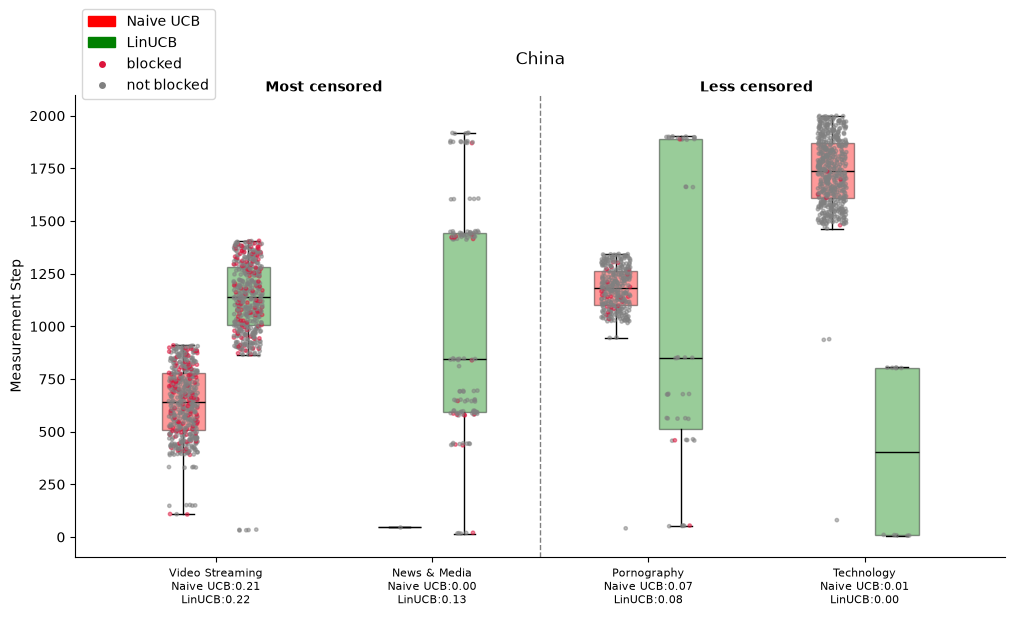

In [45]:
min_domains_China = 100   # category must have at least this many distinct domains
n_each_China = 3          # how many to take from the top and from the bottom

files_China = [
    f"{DATA_DIR}/exp1/China.csv",
    f"{DATA_DIR}/exp2/China.csv",
    # f"{DATA_DIR}/baseline/China.csv"
]

plot_scatter_boxes(files_China, min_domains_China, n_each_China, "China")
plt.savefig(f"{SCATTER_DIR}/China_policy.pdf", format="pdf", bbox_inches='tight', dpi=300)
plt.show()

                        n_domains  avg_reward
category                                     
Video Streaming               535    0.211252
News & Media                  623    0.128411
Pornography                   326    0.073865
Ecommerce                     399    0.045113
Information Technology        214    0.023551
Technology                    523    0.009771


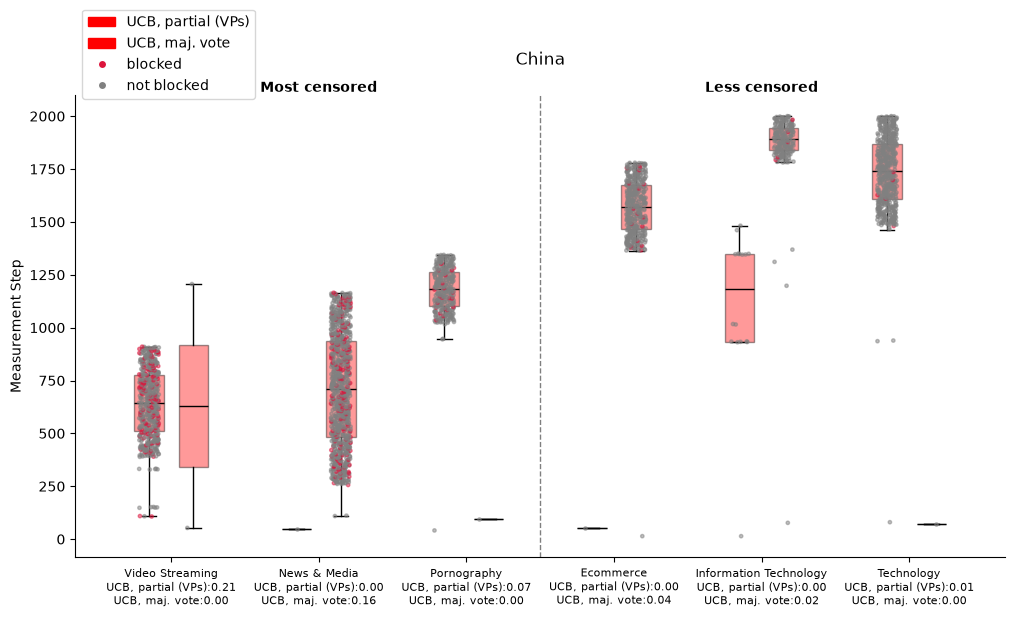

In [46]:
min_domains_China = 100   # category must have at least this many distinct domains
n_each_China = 3          # how many to take from the top and from the bottom

files_China = [
    f"{DATA_DIR}/exp5/China.csv",
    f"{DATA_DIR}/exp7/China.csv",
    # f"{DATA_DIR}/baseline/China.csv"
]

plot_scatter_boxes(files_China, min_domains_China, n_each_China, "China")
plt.savefig(f"{SCATTER_DIR}/China_reward.pdf", format="pdf", bbox_inches='tight', dpi=300)
plt.show()

### UAE

I expect this to look the most interesting when comparing majority vs partial votes?

                 n_domains  avg_reward
category                              
Pornography            327    0.259878
Social Networks        198    0.026818
Sports                 129    0.010388
Search Engines         348    0.007241


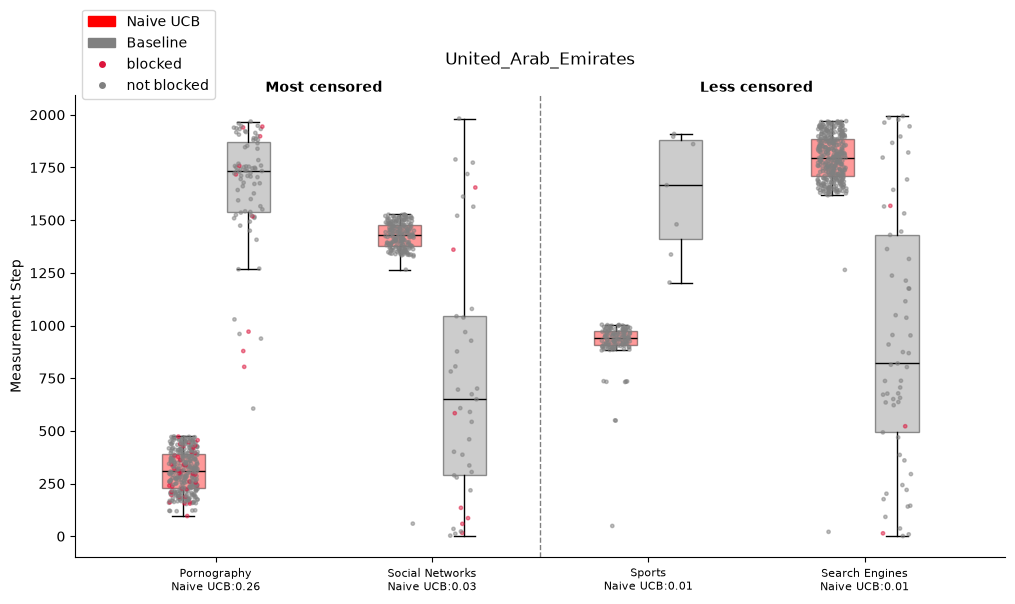

In [47]:
min_domains_UAE = 100   # category must have at least this many distinct domains
n_each_UAE = 3          # how many to take from the top and from the bottom

files_UAE = [
    f"{DATA_DIR}/exp1/United_Arab_Emirates.csv",
    # f"{DATA_DIR}/exp7/United_Arab_Emirates.csv",
    f"{DATA_DIR}/baseline/China.csv"
]

plot_scatter_boxes(files_UAE, min_domains_UAE, n_each_UAE, "United_Arab_Emirates")
plt.savefig(f"{SCATTER_DIR}/UAE_baseline.pdf", format="pdf", bbox_inches='tight', dpi=300)
plt.show()

                 n_domains  avg_reward
category                              
Pornography            327    0.259878
Social Networks        198    0.026818
Sports                 129    0.010388
Search Engines         348    0.007241


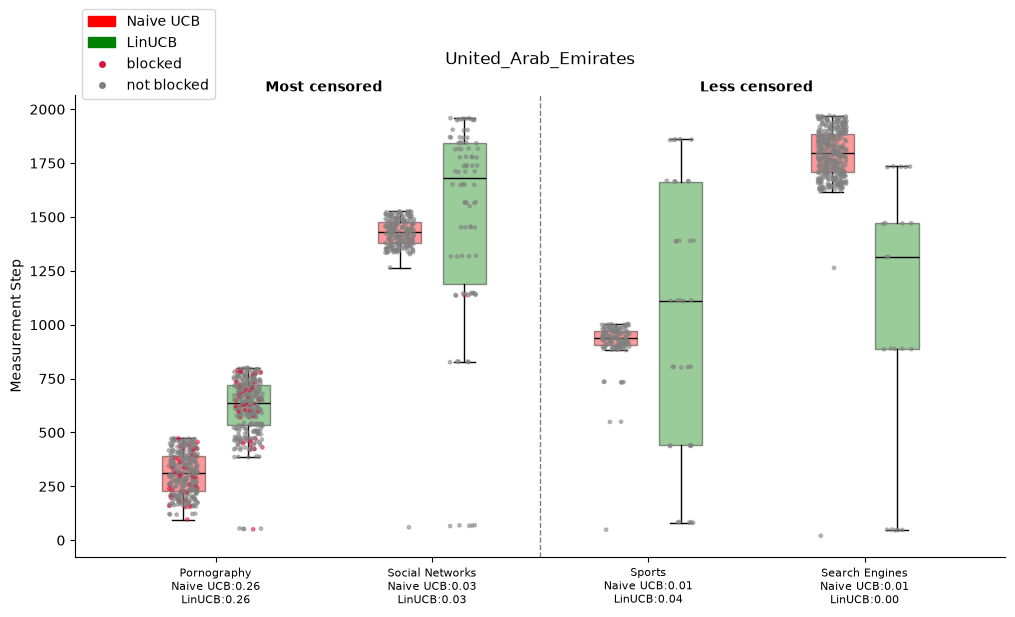

In [48]:
min_domains_UAE = 100   # category must have at least this many distinct domains
n_each_UAE = 3          # how many to take from the top and from the bottom

files_UAE = [
    f"{DATA_DIR}/exp1/United_Arab_Emirates.csv",
    f"{DATA_DIR}/exp2/United_Arab_Emirates.csv",
    # f"{DATA_DIR}/baseline/China.csv"
]

plot_scatter_boxes(files_UAE, min_domains_UAE, n_each_UAE, "United_Arab_Emirates")
plt.savefig(f"{SCATTER_DIR}/UAE_policy.pdf", format="pdf", bbox_inches='tight', dpi=300)
plt.show()

                 n_domains  avg_reward
category                              
Pornography            327    0.259878
Social Networks        198    0.026818
Sports                 129    0.010388
Advertisements         127    0.008268
Search Engines         348    0.007241
Education              427    0.003794


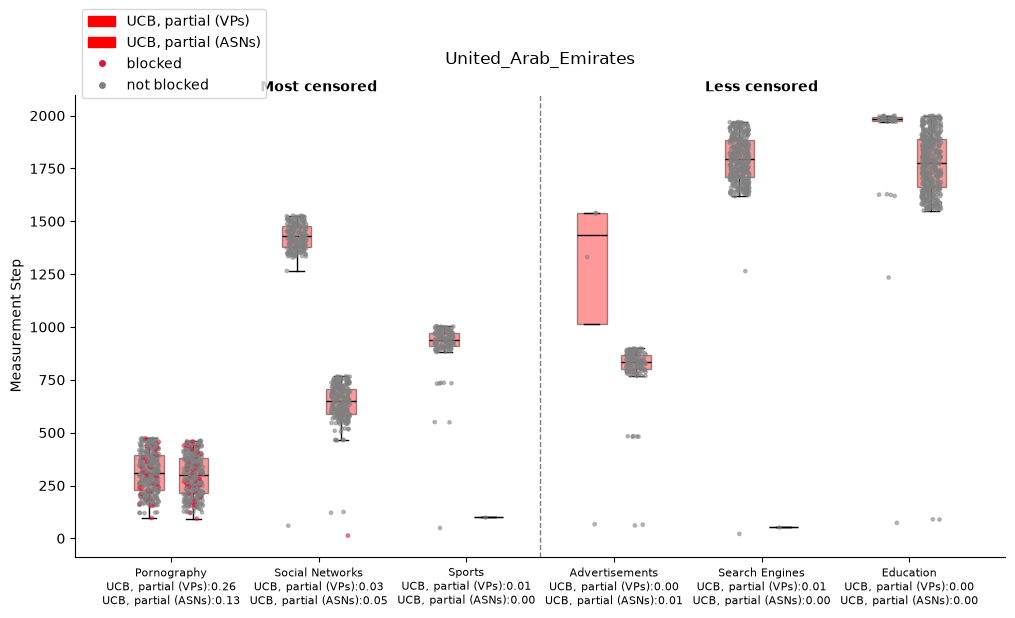

In [49]:
min_domains_UAE = 100   # category must have at least this many distinct domains
n_each_UAE = 3          # how many to take from the top and from the bottom

files_UAE = [
    f"{DATA_DIR}/exp5/United_Arab_Emirates.csv",
    f"{DATA_DIR}/exp6/United_Arab_Emirates.csv",
    # f"{DATA_DIR}/baseline/China.csv"
]

plot_scatter_boxes(files_UAE, min_domains_UAE, n_each_UAE, "United_Arab_Emirates")
plt.savefig(f"{SCATTER_DIR}/UAE_reward.pdf", format="pdf", bbox_inches='tight', dpi=300)
plt.show()

In [50]:
# all_categories, category_rewards, names, colors = get_scatter_plot_data(files, categories)

# print(len(all_categories), names)                        # one entry per run?
# for subs in all_categories:
#     print({c: len(subs[c]) for c in categories})         # rows per category
# print(all_categories[0][categories[0]].columns.tolist()) # expected column names?

In [51]:
# exp_sub = {cat: exp[exp["category"] == cat] for cat in selected}
# base_sub = {cat: base[base["category"] == cat] for cat in selected}

In [52]:
# from matplotlib.lines import Line2D
# from matplotlib.patches import Patch

# X_AXIS_OFFSET_SCALE = 1
# BETWEEN_BOX_OFFSET_SCALE = 0.3
# PLOT_LENGTH_SCALE = 0.5
# BOX_WIDTH = 0.2

# def box_x(i, offset):
#     return X_AXIS_OFFSET_SCALE * i + offset * BETWEEN_BOX_OFFSET_SCALE

# # plot length should be dependent on # categories and # runs
# num_categories = len(categories)
# num_runs = len(files)

# # fig, ax = plt.subplots(figsize=(num_categories * num_runs * PLOT_LENGTH_SCALE, 6))
# fig, ax = plt.subplots(figsize=(12, 6))

# # need a list of idx, run subsets, rewards, names, colors
# # run subsets are the measurements that match each category for every category, so actually a 

# all_categories, category_rewards, names, colors = get_scatter_plot_data(files, categories)

# for i, cat in enumerate(categories):
#     for offset, subs, color in zip(range(len(all_categories)), all_categories, colors):
#         data = subs[cat]["time"].to_numpy()
#         bp = ax.boxplot([data], 
#                         positions=[box_x(i, offset)], 
#                         widths=BOX_WIDTH,
#                         patch_artist=True, showfliers=False,
#                         medianprops={"color": "black"})
#         bp["boxes"][0].set_facecolor(color)
#         bp["boxes"][0].set_alpha(0.4)   # make the box semi-transparent

# rng = np.random.default_rng(0)  # fixed seed -> same jitter every run

# JITTER_HALF_LENGTH = BOX_WIDTH / 3
# for i, cat in enumerate(categories):
#     for offset, subs in zip(range(len(all_categories)), all_categories):
#         pts = subs[cat]
#         # spread points sideways around the box center (box half-width is 0.5)
#         x = box_x(i, offset) + rng.uniform(-JITTER_HALF_LENGTH, JITTER_HALF_LENGTH, size=len(pts))
#         point_colors = np.where(pts["is_blocked"] == 1, "crimson", "gray")
#         ax.scatter(x, pts["time"], c=point_colors, s=6, alpha=0.5, zorder=3)

# labels = []
# # iterate over cat, then run
# for cat in categories:
#     label = cat
#     for name, reward in zip(names, category_rewards):
#         label = f"{label}\n{name}:{reward[cat]:.2f}"
#     labels.append(label)

# ax.set_xticks([box_x(i, (num_runs - 1) / 2) for i in range(len(categories))])
# ax.set_xticklabels(labels, fontsize=8)

# ax.set_ylabel("Measurement Step")
# ax.set_title("Iran: When Each Category was Tried", pad=22)

# # categories before this index are the "top" group, the rest are "bottom"
# split = num_categories // 2
# # halfway between the last box of the previous group and the first box of the next
# divider_x = (box_x(split - 1, num_runs - 1) + box_x(split, 0)) / 2
# ax.axvline(divider_x, color="black", linestyle="--", linewidth=1, alpha=0.5, zorder=0)

# # Below is code to add labels to each side on the top
# # can comment out and remove title padding if space needed
# # x-range covered by the boxes on each side of the divider
# left_center = (box_x(0, 0) + box_x(split - 1, num_runs - 1)) / 2
# right_center = (box_x(split, 0) + box_x(num_categories - 1, num_runs - 1)) / 2
# # x in data units, y in axes units (1.0 = top edge of the plot)
# xform = ax.get_xaxis_transform()
# ax.text(left_center, 1.0, "Most censored", transform=xform,
#         ha="center", va="bottom", fontsize=10, fontweight="bold")
# ax.text(right_center, 1.0, "Less censored", transform=xform,
#         ha="center", va="bottom", fontsize=10, fontweight="bold")

# handles = [Patch(color=color, label=name) for color, name in zip(colors, names)]
# handles.append(Line2D([0], [0], marker="o", color="w", markerfacecolor="crimson", label="blocked"))
# handles.append(Line2D([0], [0], marker="o", color="w", markerfacecolor="gray", label="not blocked"))
# ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(0.0, 1.2))
# ax.spines[["top", "right"]].set_visible(False)
# plt.show()

## Heat map

In [53]:
# this looks a little different because I made Claude do this without
# the context from the rest of the notebook
TOP_N = 20

countries = ["China", "Germany", "Iran", "Thailand", "Turkey",
             "United Arab Emirates", "Vietnam"]

In [54]:
def count_by_category(column_files):
    blocked, tested = {}, {}
    for label, path in column_files.items():
        grouped = load_run(path).groupby("category")["is_blocked"]
        blocked[label] = grouped.sum()    # how many measurements were blocked
        tested[label] = grouped.count()   # how many measurements were made
    # one row per category, one column per label; 0 where a category was never tried
    blocked = pd.DataFrame(blocked).fillna(0).astype(int)
    tested = pd.DataFrame(tested).fillna(0).astype(int)
    return blocked, tested

In [55]:
def plot_heatmap(column_files, exp_name, xaxis="Country"):
    blocked, tested = count_by_category(column_files)
    
    # rank categories by total blocked measurements across ALL columns
    top_categories = blocked.sum(axis=1).nlargest(TOP_N).index
    
    # ends up being ordered by count of blocked domains across all countries
    # call sort_index() on each of these to sort alphabetically instead
    blocked_top = blocked.loc[top_categories]
    tested_top = tested.loc[top_categories]
    
    # block rate; NaN (not 0%) where nothing was tested, so those cells stay distinguishable
    rate = blocked_top / tested_top.replace(0, np.nan)

    fig, ax = plt.subplots(figsize=(11, 9))

    cmap = plt.get_cmap("YlOrRd").copy()
    cmap.set_bad("lightgray")   # untested cells show as gray
    
    im = ax.imshow(np.ma.masked_invalid(rate.to_numpy()),
                   cmap=cmap, vmin=0, vmax=1, aspect="auto")
    
    # axis labels come straight from the table, so any new columns appear automatically
    ax.set_xticks(range(rate.shape[1]))
    ax.set_xticklabels(rate.columns)
    ax.set_yticks(range(rate.shape[0]))
    ax.set_yticklabels(rate.index)
    
    # thin white lines between cells (minor ticks sit on the cell borders)
    ax.set_xticks(np.arange(-0.5, rate.shape[1], 1), minor=True)
    ax.set_yticks(np.arange(-0.5, rate.shape[0], 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=1)
    ax.tick_params(which="minor", length=0)
    
    for r in range(rate.shape[0]):
        for c in range(rate.shape[1]):
            b = blocked_top.iat[r, c]
            t = tested_top.iat[r, c]
            value = rate.iat[r, c]
    
            pct = "n/a" if np.isnan(value) else f"{value:.0%}"
            color = "white" if value > 0.6 else "black"   # readable on dark cells
    
            ax.text(c, r, f"{b}/{t}",
            # ax.text(c, r, f"{b}/{t}\n({pct})",
                    ha="center", va="center", fontsize=12, color=color)
    
    cbar = fig.colorbar(im, ax=ax, shrink=0.6)
    cbar.ax.set_xlabel("Block Rate")
    
    ax.set_title(f"Blocking Rate by Category × {xaxis}, {exp_name}", fontweight="bold")
    plt.tight_layout()

In [56]:
HEATMAP_DIR = "./figures/category_rates"

COUNTRY_CODE_MAP = {
    "China" : "CN", 
    "Germany" : "DE", 
    "Iran" : "IR", 
    "Thailand" : "TH", 
    "Turkey" : "TU",
    "United Arab Emirates" : "AE", 
    "Vietnam" : "VN"
}


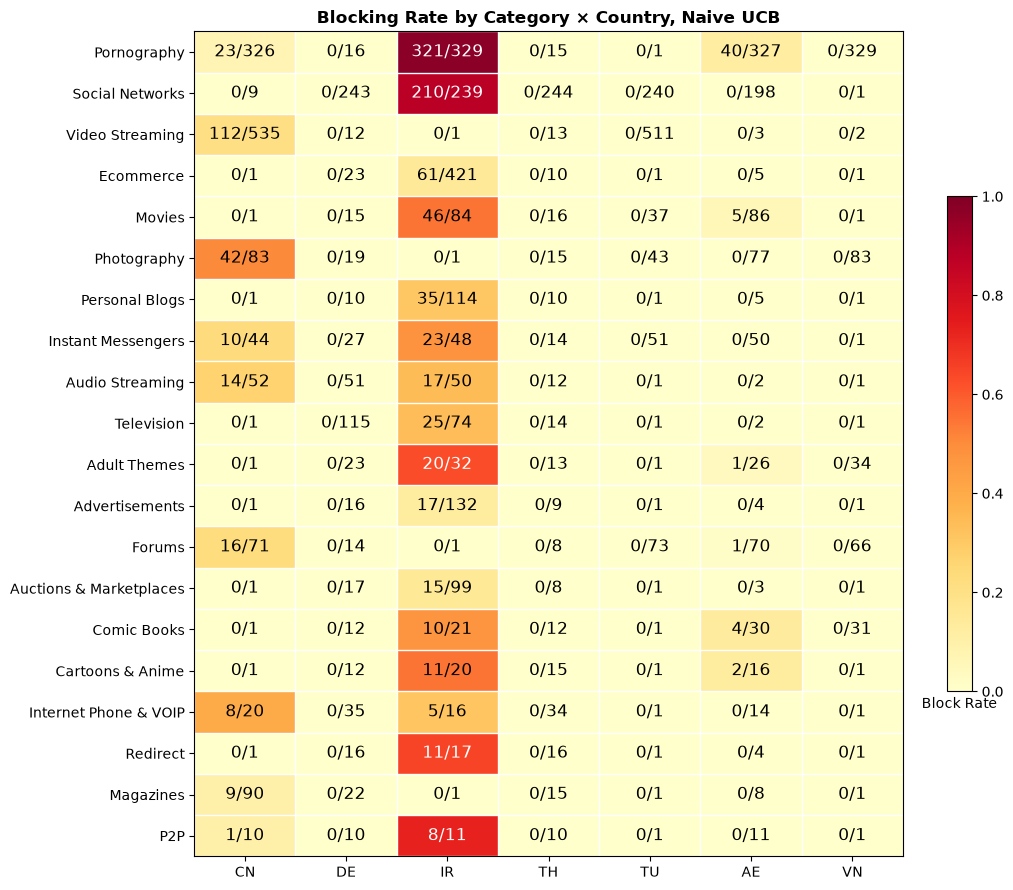

In [57]:
# {column label -> CSV file}. Each entry becomes one column in the heatmap.
column_files_exp1 = {c: f"{DATA_DIR}/exp1/{c.replace(' ', '_')}.csv" for c in countries}
column_files_exp1 = {COUNTRY_CODE_MAP[k]: v for k, v in column_files_exp1.items()}
plot_heatmap(column_files_exp1, "Naive UCB")
plt.savefig(f"{HEATMAP_DIR}/countries_naiveucb.pdf", format="pdf", bbox_inches='tight', dpi=300)
plt.show()

In [58]:
votes = pd.read_csv(f"{DATA_DIR}/asn_votes_exp6.csv")

# A domain counts as blocked in an ASN if at least this fraction of that
# ASN's votes saw blocking. 0.5 = majority.
BLOCK_THRESHOLD = 0.5
votes["is_blocked"] = votes["vote_fraction"] >= BLOCK_THRESHOLD

In [59]:
def count_by_category_asn(votes, country):
    sub = votes[votes["country"] == country]
    grouped = sub.groupby(["category", "asn"])["is_blocked"]
    blocked = grouped.sum().unstack(fill_value=0).astype(int)   # domains blocked
    tested = grouped.count().unstack(fill_value=0)              # domains tested
    return blocked, tested

In [60]:
def select_top(blocked, tested, top_n=20):
    blocked = blocked[blocked.sum(axis=1) > 0]
    
    # total blocked domains per category, summed across ALL of the country's ASNs
    total_blocked = blocked.sum(axis=1)
    top_categories = total_blocked.nlargest(top_n).index   # highest -> lowest

    # .loc with this index keeps the ranking order (no re-sorting)
    blocked_top = blocked.loc[top_categories]
    tested_top = tested.loc[top_categories]

    # ASNs with the most blocking first, as before
    asn_order = blocked_top.sum(axis=0).sort_values(ascending=False).index
    blocked_top, tested_top = blocked_top[asn_order], tested_top[asn_order]

    rate = blocked_top / tested_top.replace(0, np.nan)
    return blocked_top, tested_top, rate

In [61]:
def draw_grid(rate, small):
    fig, ax = plt.subplots(figsize=(11, 8))
    cmap = plt.get_cmap("YlOrRd").copy()
    cmap.set_bad("lightgray")
    im = ax.imshow(np.ma.masked_invalid(rate.to_numpy()),
                   cmap=cmap, vmin=0, vmax=1, aspect="auto")

    ax.set_yticks(range(rate.shape[0]))
    ax.set_yticklabels(rate.index)

    
    if small:   # few ASNs: label each column and draw white gridlines
        ax.set_xticks(range(rate.shape[1]))
        ax.set_xticklabels(rate.columns, rotation=30, ha="right")
        ax.set_xticks(np.arange(-0.5, rate.shape[1], 1), minor=True)
        ax.set_yticks(np.arange(-0.5, rate.shape[0], 1), minor=True)
        ax.grid(which="minor", color="white", linewidth=1)
        ax.tick_params(which="minor", length=0)
    else:
        ax.set_xticks([])
    # if small:   # few ASNs: label each column and draw white gridlines
    #     ax.set_xticks(range(rate.shape[1]))
    #     ax.set_xticklabels(rate.columns, rotation=30, ha="right")
    #     ax.set_xticks(np.arange(-0.5, rate.shape[1], 1), minor=True)
    #     ax.set_yticks(np.arange(-0.5, rate.shape[0], 1), minor=True)
    #     ax.grid(which="minor", color="white", linewidth=1)
    #     ax.tick_params(which="minor", length=0)
    # else:       # many ASNs: no per-column labels
        # ax.set_xticks([])

    ax.set_xlabel(f"ASNs (n = {rate.shape[1]})")
    return fig, ax, im

In [62]:
def annotate_cells(ax, blocked_top, tested_top, rate):
    for r in range(rate.shape[0]):
        for c in range(rate.shape[1]):
            b, t, value = blocked_top.iat[r, c], tested_top.iat[r, c], rate.iat[r, c]
            pct = "n/a" if np.isnan(value) else f"{value:.0%}"
            color = "white" if value > 0.6 else "black"
            # ax.text(c, r, f"{b}/{t}\n({pct})",
            ax.text(c, r, f"{b}/{t}",
                    ha="center", va="center", fontsize=9, color=color)

In [63]:
SMALL_MAX_COLUMNS = 15   # at or below this, label and annotate every ASN

def create_asn_heatmap(votes, country, top_n=20):
    blocked, tested = count_by_category_asn(votes, country)
    blocked_top, tested_top, rate = select_top(blocked, tested, top_n)

    small = rate.shape[1] <= SMALL_MAX_COLUMNS
    # small = False
    fig, ax, im = draw_grid(rate, small)
    if small:
        annotate_cells(ax, blocked_top, tested_top, rate)

    cbar = fig.colorbar(im, ax=ax, shrink=0.6)
    cbar.ax.set_xlabel("Block Rate")
    ax.set_title(f"Blocking Rate by Category × ASN: {country}", fontweight="bold")
    plt.tight_layout()
    

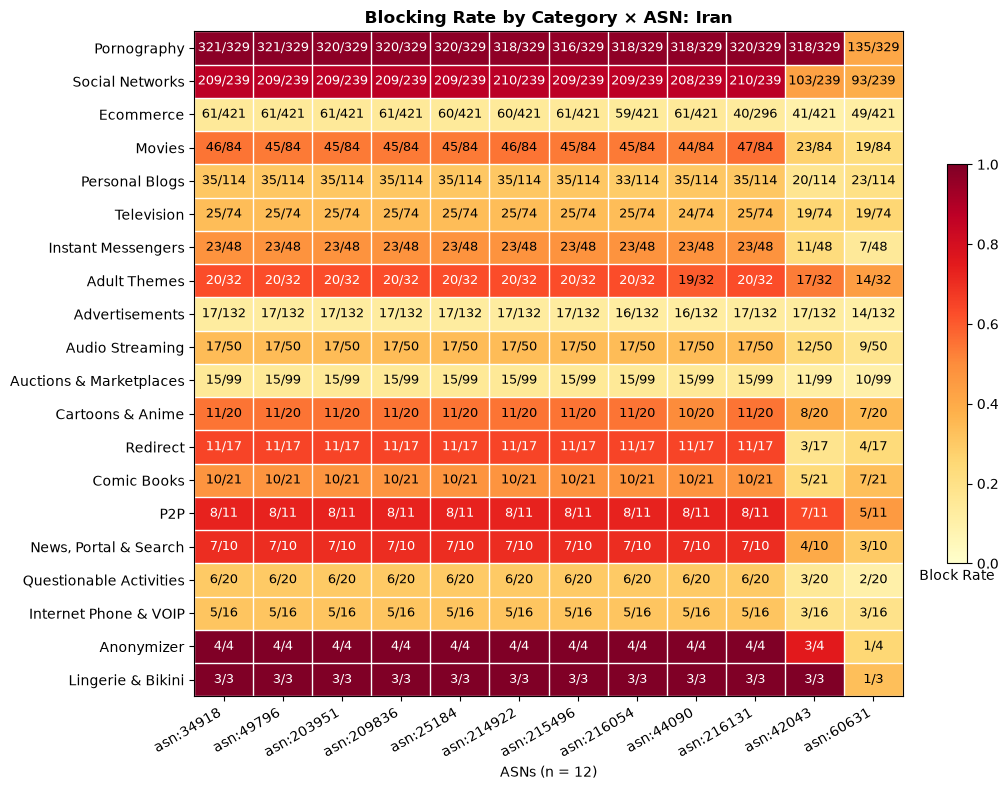

In [64]:
create_asn_heatmap(votes, "Iran")
plt.savefig(f"{HEATMAP_DIR}/asns_iran.pdf", format="pdf", bbox_inches='tight', dpi=300)
plt.show()

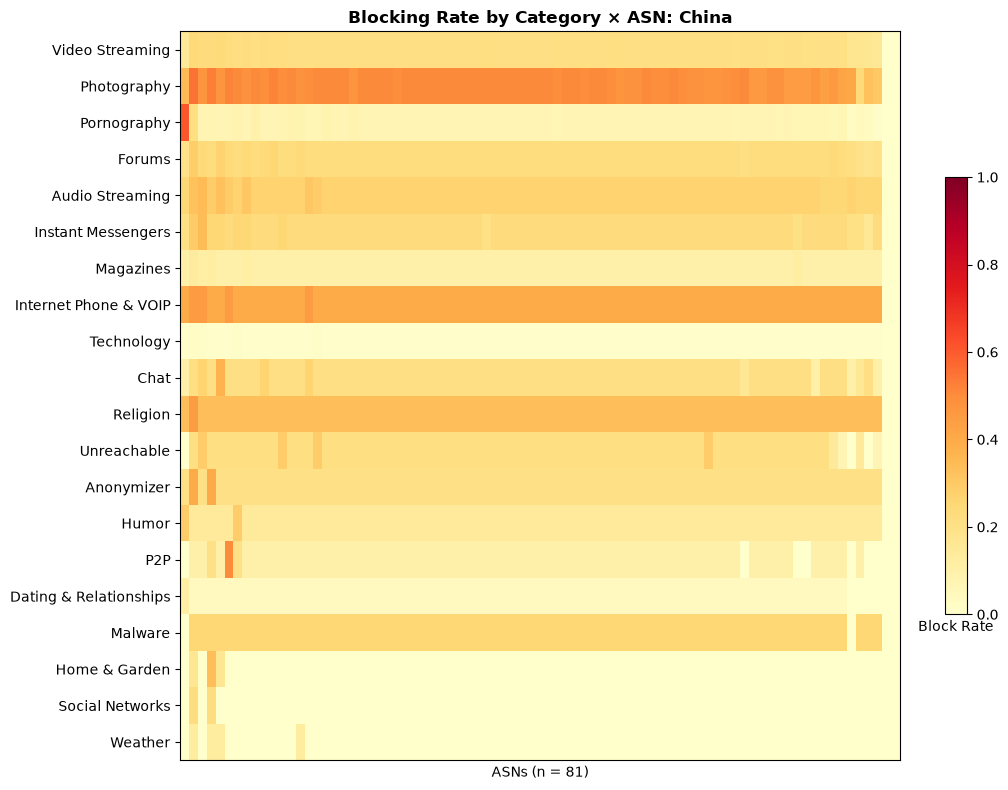

In [65]:
create_asn_heatmap(votes, "China")
plt.savefig(f"{HEATMAP_DIR}/asns_china.pdf", format="pdf", bbox_inches='tight', dpi=300)
plt.show()

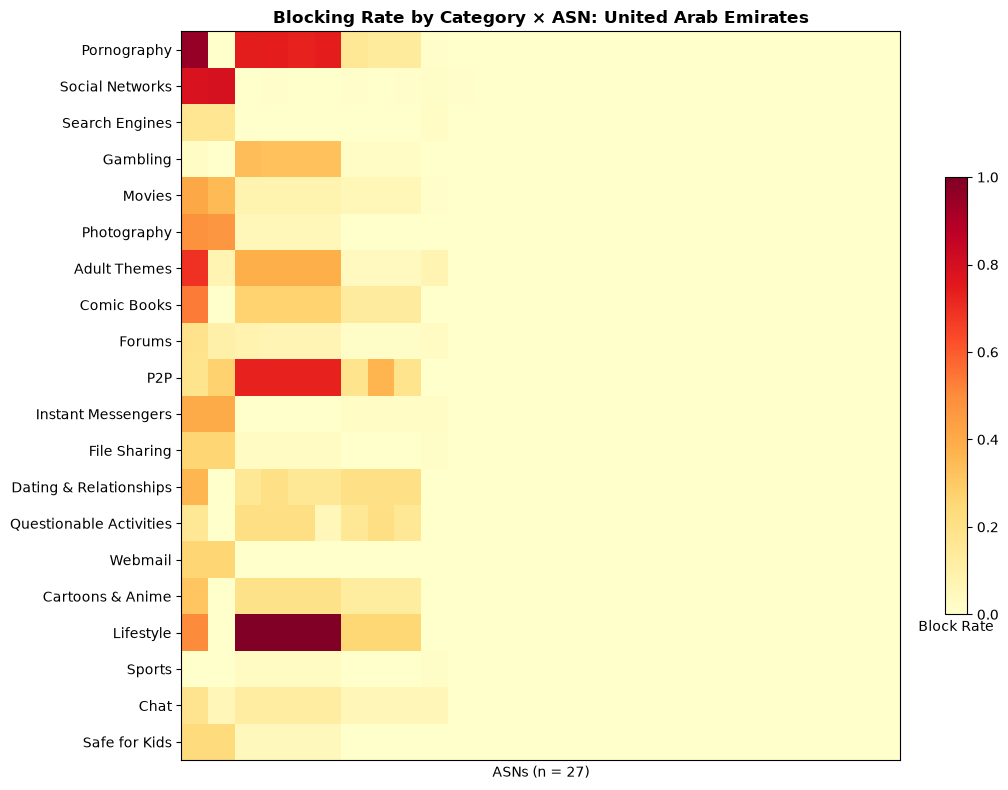

In [66]:
create_asn_heatmap(votes, "United Arab Emirates")
plt.savefig(f"{HEATMAP_DIR}/asns_uae.pdf", format="pdf", bbox_inches='tight', dpi=300)
plt.show()

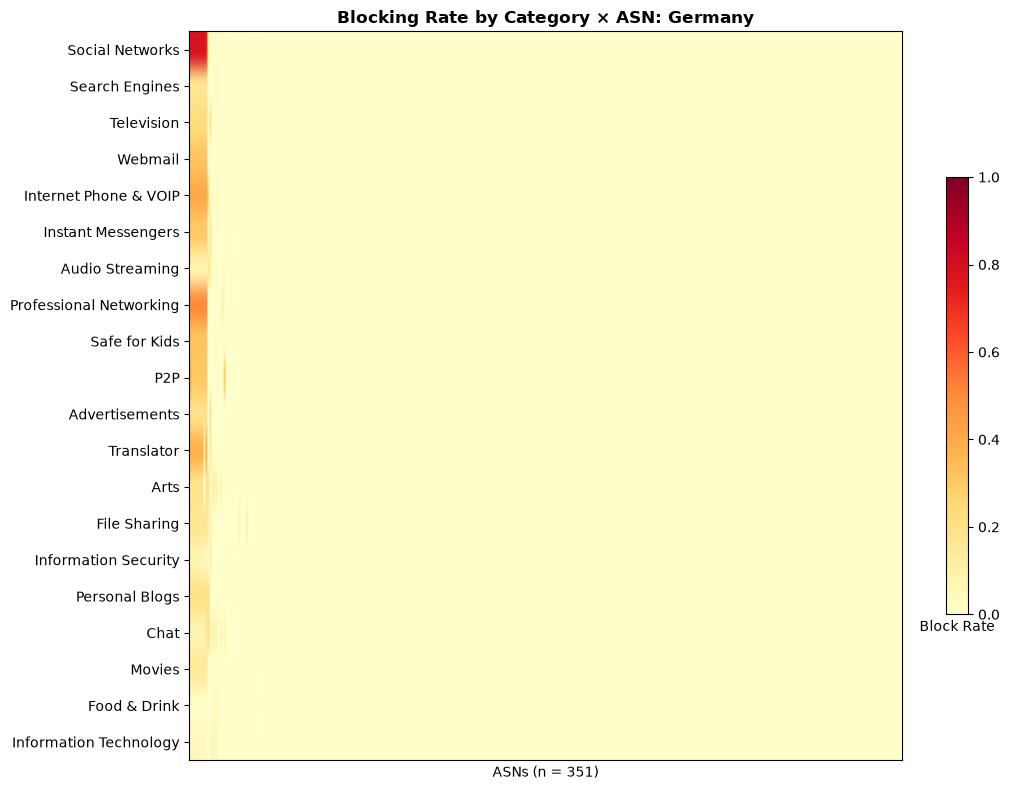

In [67]:
create_asn_heatmap(votes, "Germany")
plt.savefig(f"{HEATMAP_DIR}/asns_germany.pdf", format="pdf", bbox_inches='tight', dpi=300)
plt.show()

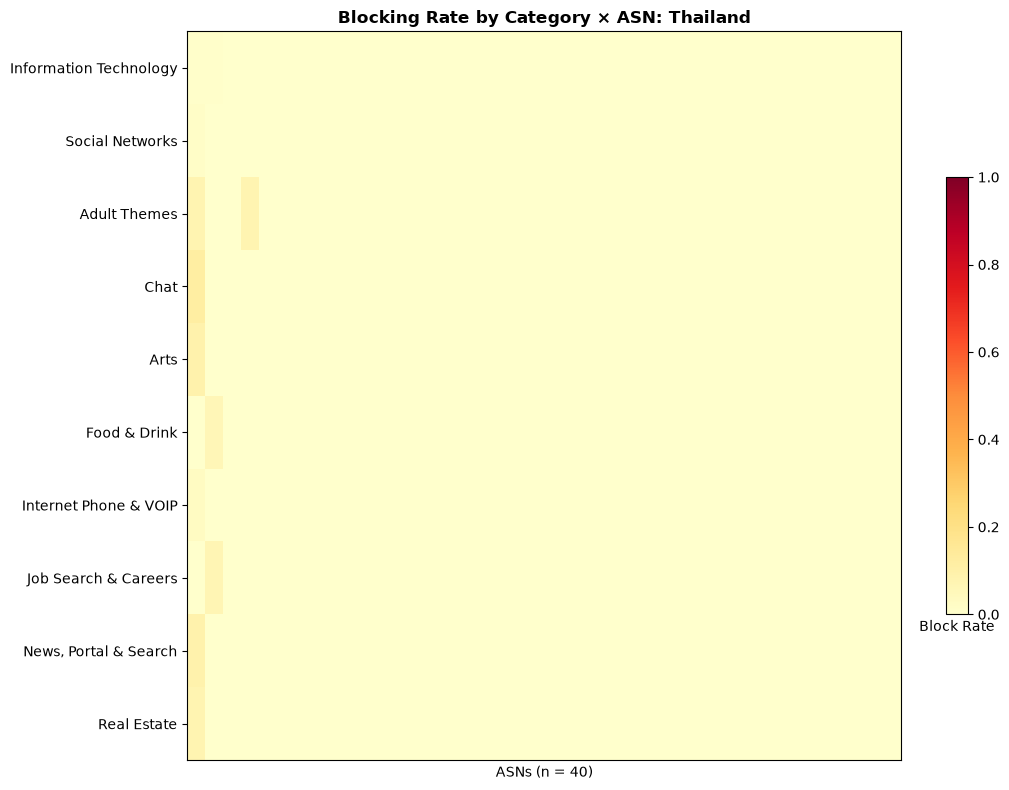

In [68]:
create_asn_heatmap(votes, "Thailand")
plt.savefig(f"{HEATMAP_DIR}/asns_thailand.pdf", format="pdf", bbox_inches='tight', dpi=300)
plt.show()

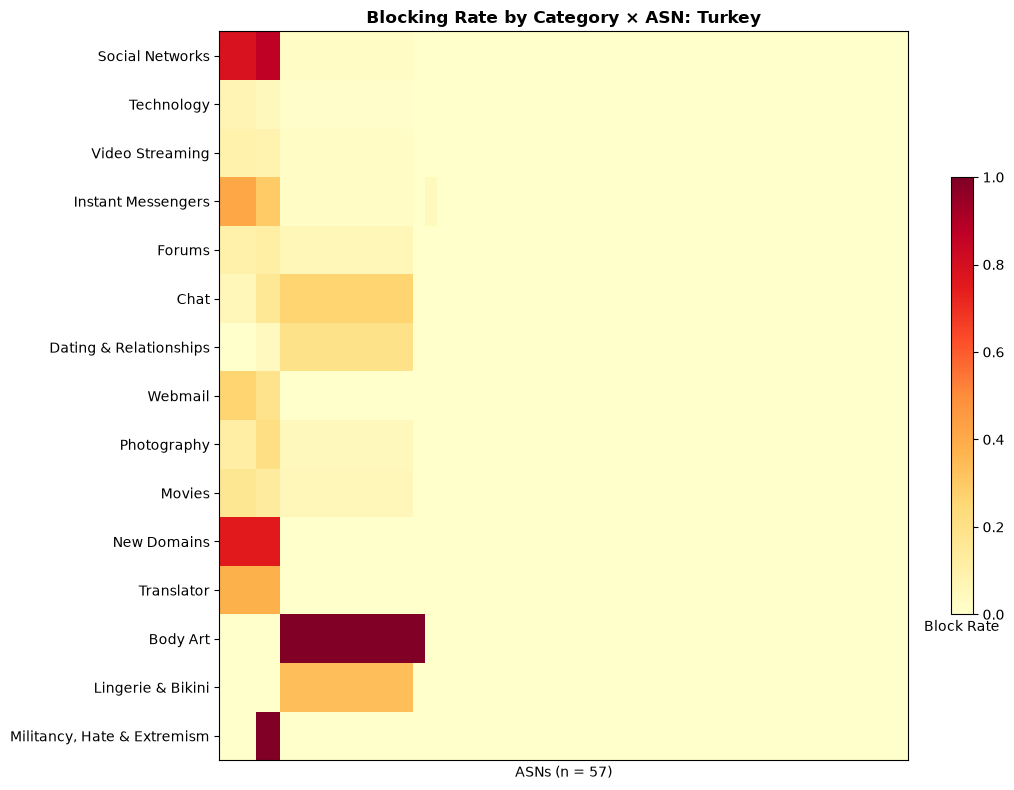

In [69]:
create_asn_heatmap(votes, "Turkey")
plt.savefig(f"{HEATMAP_DIR}/asns_turkey.pdf", format="pdf", bbox_inches='tight', dpi=300)
plt.show()

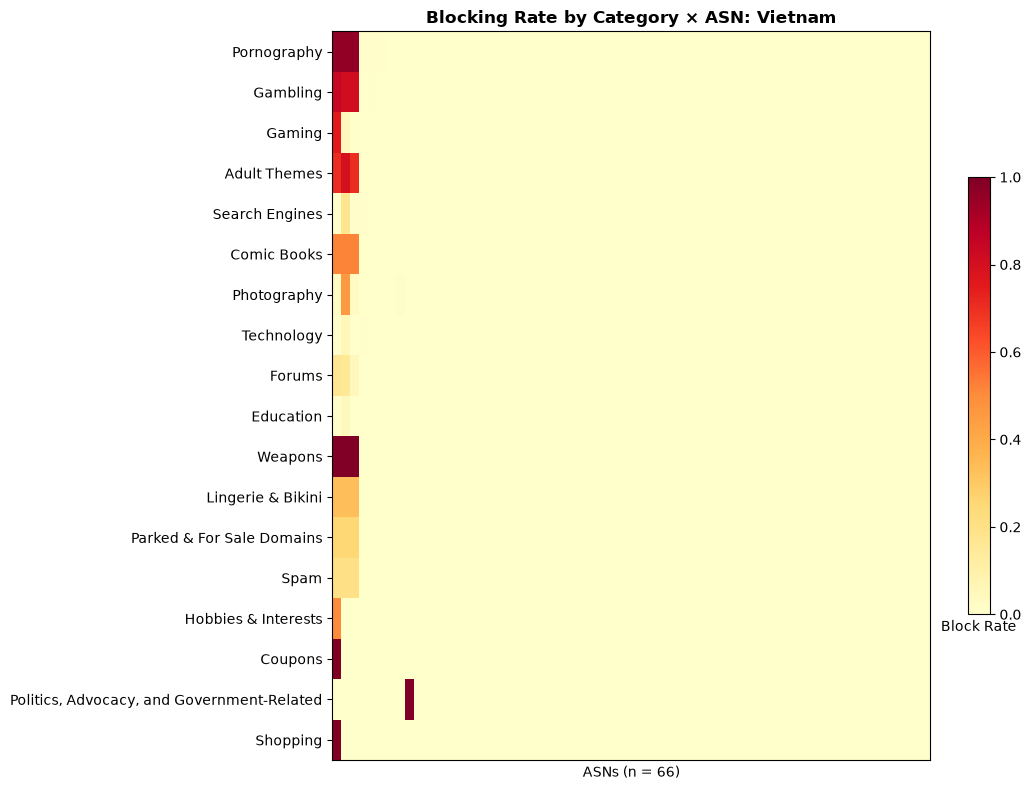

In [70]:
create_asn_heatmap(votes, "Vietnam")
plt.savefig(f"{HEATMAP_DIR}/asns_vietnam.pdf", format="pdf", bbox_inches='tight', dpi=300)
plt.show()

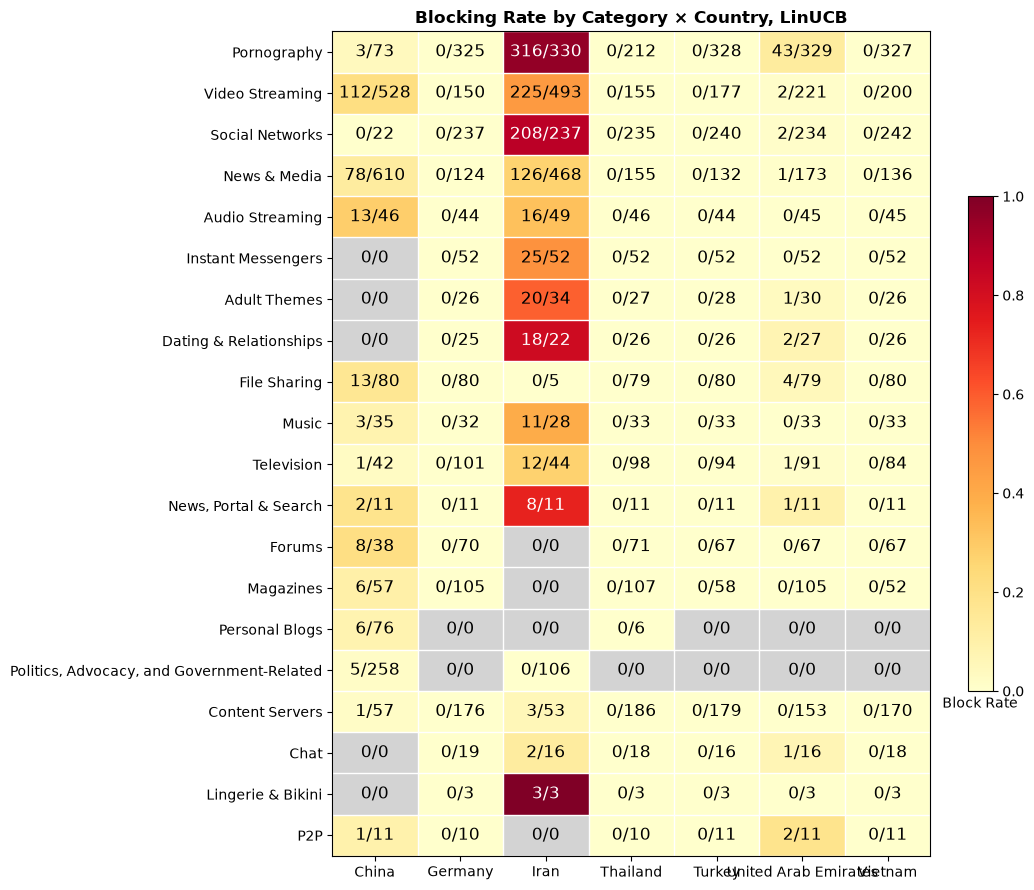

In [71]:
# {column label -> CSV file}. Each entry becomes one column in the heatmap.
column_files_exp3 = {c: f"{DATA_DIR}/exp3/{c.replace(' ', '_')}.csv" for c in countries}
plot_heatmap(column_files_exp3, "LinUCB")
plt.savefig(f"{HEATMAP_DIR}/countries_linucb.pdf", format="pdf", bbox_inches='tight', dpi=300)
plt.show()

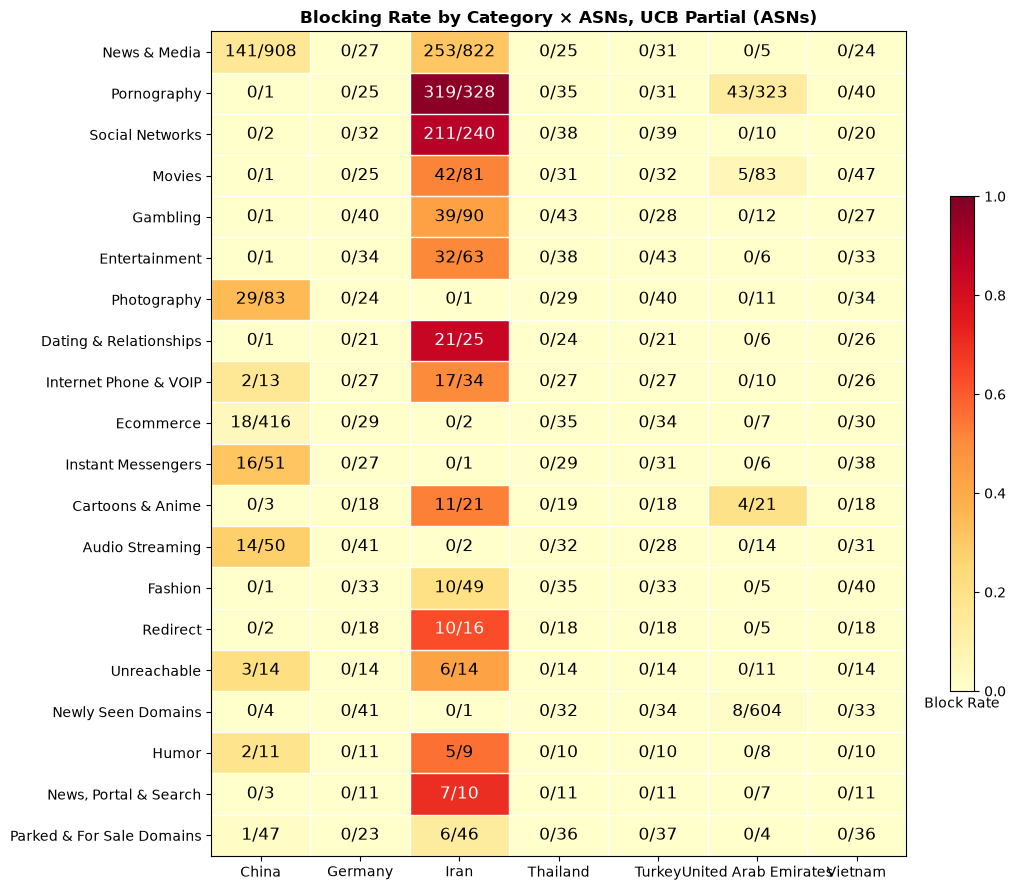

In [72]:
# {column label -> CSV file}. Each entry becomes one column in the heatmap.
column_files_exp7 = {c: f"{DATA_DIR}/exp7/{c.replace(' ', '_')}.csv" for c in countries}
plot_heatmap(column_files_exp7, "UCB Partial (ASNs)", "ASNs")

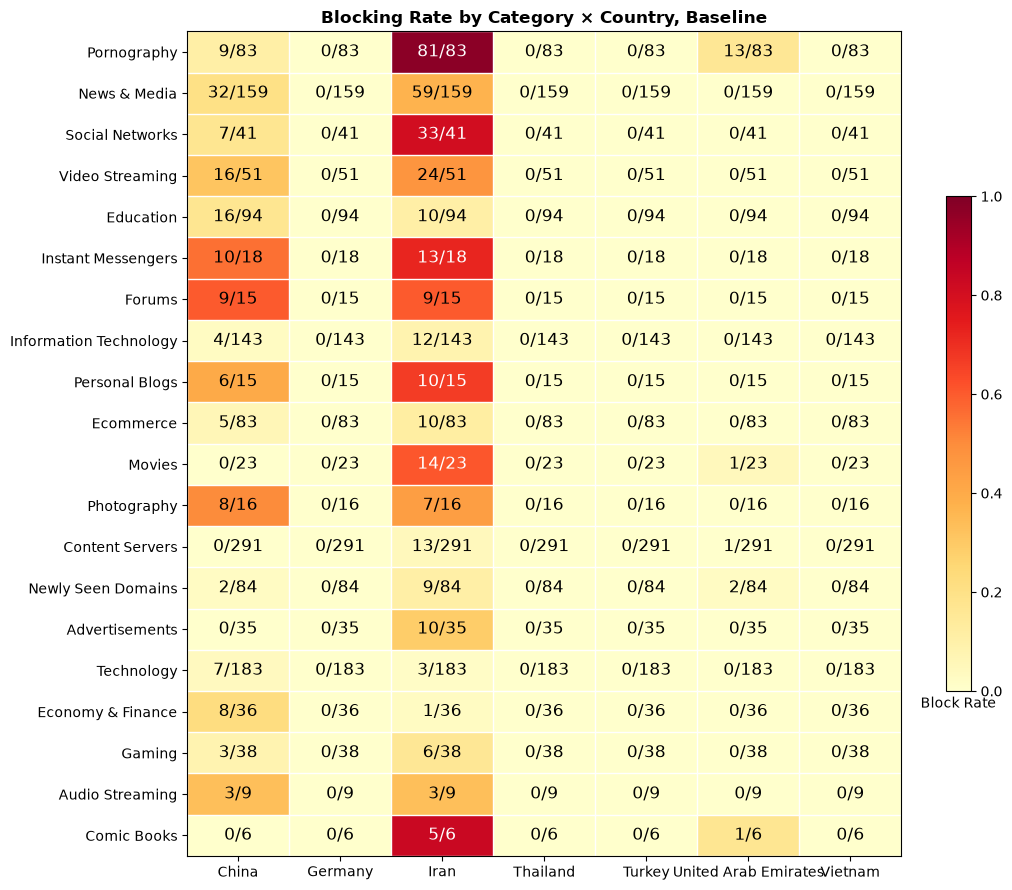

In [73]:
# {column label -> CSV file}. Each entry becomes one column in the heatmap.
column_files_baseline = {c: f"{DATA_DIR}/baseline/{c.replace(' ', '_')}.csv" for c in countries}
plot_heatmap(column_files_baseline, "Baseline")
plt.savefig(f"{HEATMAP_DIR}/countries_baseline.pdf", format="pdf", bbox_inches='tight', dpi=300)
plt.show()

## Arm selection over time

In [74]:
NUM_ARMS_TO_COMPARE = 10

exp = load_run(f"{DATA_DIR}/exp1/Iran.csv")

top_arms = exp["category"].value_counts().head(NUM_ARMS_TO_COMPARE).index
print(list(top_arms))  # check which categories were picked

['Ecommerce', 'Pornography', 'Social Networks', 'Advertisements', 'Personal Blogs', 'Information Security', 'Auctions & Marketplaces', 'Movies', 'Television', 'No Content']


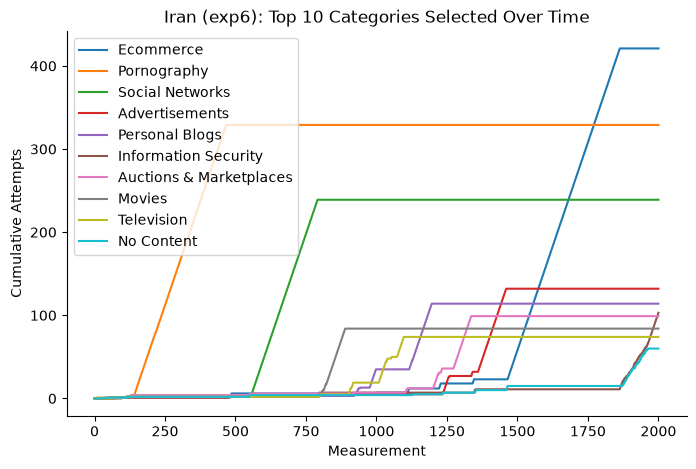

In [75]:
fig, ax = plt.subplots(figsize=(8, 5))
for cat in top_arms:
    # True/False per measurement -> running total of times this arm was picked
    ax.plot(exp["time"], (exp["category"] == cat).cumsum(), label=cat)

ax.set_xlabel("Measurement")
ax.set_ylabel("Cumulative Attempts")
ax.set_title(f"Iran (exp6): Top {NUM_ARMS_TO_COMPARE} Categories Selected Over Time")
ax.spines[["top", "right"]].set_visible(False)
ax.legend()
plt.show()